We study Value, Profitability and Momentum in twenty Chinese A-share companies. We use EBIT divided by our enterprise-value estimate for Value. For Profitability, we divide EBIT by average invested capital. Momentum uses earlier price returns and volatility.

All twenty stocks use the same daily dates, from 1 February 2016 to 9 October 2026. The company table shows the names and businesses we selected. We focus on companies outside banking and insurance so we can apply the same capital rules across the group.

We trained eleven forecasting models, including Random Forest, XGBoost, MLP, LSTM and CNN. Each model estimates the next month's return for the three factor portfolios. We use these forecasts to choose their weights. We also compare different factor measures, input periods, random seeds and trading costs. The tables and charts show what we found.

In [1]:
from pathlib import Path
import contextlib
import io
import logging
import warnings
import torch
from torch import nn
from prophet import Prophet
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
from sklearn.ensemble import RandomForestRegressor
from IPython.display import display
from importlib.metadata import version
import hashlib

In [2]:
pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})

shell = get_ipython()
if shell is not None:
    with contextlib.redirect_stdout(io.StringIO()):
        shell.run_line_magic('xmode', 'Minimal')

In [3]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'inputs/china_stock_ebit').is_dir())
INPUTS = ROOT / 'inputs/china_stock_ebit'
RESULTS = ROOT / 'results/china_stock_ebit_v3'
RESULTS.mkdir(parents=True, exist_ok=True)
companies = pd.read_csv(INPUTS / 'stocks.csv').set_index('ticker')
STOCKS = companies.index.tolist()
if len(STOCKS) != 20 or len(set(STOCKS)) != 20:
    raise ValueError('This experiment requires exactly 20 different A-share companies.')
if not companies.index.str.fullmatch(r'(?:6[0-9]{5}\.SH|[03][0-9]{5}\.SZ)').all():
    raise ValueError('Use Shanghai or Shenzhen A-share stock codes.')

company_table = companies.reset_index()[['name', 'ticker', 'business']].rename(columns={'name': 'Company', 'ticker': 'A-share code', 'business': 'Main business'})
company_table.index = range(1, len(company_table) + 1)
company_table.index.name = '#'
print(f'{len(companies)} companies')
display(company_table)

20 companies


,Company,A-share code,Main business
#,,,
1,NAURA Technology,002371.SZ,Semiconductor manufacturing equipment
2,Wanhua Chemical,600309.SH,Chemicals and advanced materials
3,Midea Group,000333.SZ,Home appliances and industrial automation
4,Haier Smart Home,600690.SH,Home appliances and smart-home products
5,ZTE,000063.SZ,Telecommunications equipment and mobile devices
6,TCL Technology,000100.SZ,Display panels and semiconductor materials
7,BOE Technology,000725.SZ,Electronic displays
8,Hikvision,002415.SZ,Video and security equipment
9,SAIC Motor,600104.SH,"Cars and commercial vehicles, including MG"


Our daily prices come from Tencent. We use its hfq-adjusted prices to calculate returns and its raw A-share prices to estimate company value. The detailed income statements and balance sheets come from Eastmoney. We also checked annual reports where interest expense was missing. The source tables show the fields, dates and any report-based corrections.

All twenty stocks have the same dates in the saved price files. We kept a date only when every stock had both prices. We did not fill missing days with an earlier price. The original downloads stay separate from these aligned files. The price table below shows the common period and the same number of observations for every company.

Prices cover more years than the usable EBIT figures. We use annual EBIT from 2017 onward, with the previous year's balance sheet for opening capital. We wait until the statement has been announced and at least six months have passed after year-end. We also check the date of the opening balance sheet. A statement expires eighteen months after year-end. The saved statement history can contain later revisions; we record the update dates alongside the announcement dates.

We have nine usable financial years for each company, from 2017 to 2025. This gives us 180 annual rows. The 2016 balance sheets give the opening capital for 2017.

In [4]:
PRICE_START = pd.Timestamp('2016-02-01')
PRICE_END = pd.Timestamp('2026-10-09')

price_parts = []
raw_parts = []
share_history = {}
for stock in STOCKS:
    frame = pd.read_csv(INPUTS / f'{stock}_prices.csv', parse_dates=['date'])
    frame = frame.loc[frame.date.between(PRICE_START, PRICE_END)].sort_values('date')
    values = frame[['close', 'raw_close']]
    if frame.date.duplicated().any() or values.isna().any().any() or values.le(0).any().any() or not np.isfinite(values).all().all():
        raise ValueError(f'Check prices for {stock}.')
    if len(frame) < 2000 or frame.date.min() != PRICE_START or frame.date.max() != PRICE_END:
        raise ValueError(f'Check the fixed price period for {stock}.')
    price_parts.append(frame.set_index('date').close.rename(stock))
    raw_parts.append(frame.set_index('date').raw_close.rename(stock))
    shares = pd.read_csv(INPUTS / f'{stock}_shares.csv', parse_dates=['effective_date', 'published_date']).rename(columns={'published_date': 'notice_date', 'totalshares': 'shares'})
    shares = shares.dropna(subset=['effective_date', 'notice_date', 'shares'])
    shares = shares.loc[shares.shares > 0].copy()
    shares['available_date'] = shares[['effective_date', 'notice_date']].max(axis=1)
    share_history[stock] = shares.sort_values(['effective_date', 'available_date'])

prices = pd.concat(price_parts, axis=1, sort=True).sort_index()
raw_prices = pd.concat(raw_parts, axis=1, sort=True).sort_index()
if prices.isna().any().any() or raw_prices.isna().any().any() or not prices.index.equals(raw_prices.index):
    raise ValueError('Every company must use the same complete daily dates.')
weekly = prices.resample('W-FRI').last().dropna()
weekly_returns = weekly.pct_change(fill_method=None)
prices.to_csv(RESULTS / 'aligned_adjusted_prices.csv', index_label='date')
raw_prices.to_csv(RESULTS / 'aligned_raw_prices.csv', index_label='date')
coverage = pd.DataFrame([{'stock': stock, 'first_date': prices[stock].first_valid_index(), 'last_date': prices[stock].last_valid_index(), 'observations': prices[stock].count()} for stock in STOCKS]).set_index('stock')
if coverage.nunique().ne(1).any():
    raise ValueError('The start, end and daily counts must match for every stock.')
coverage.to_csv(RESULTS / 'price_checks.csv')
coverage_table = companies[['name']].join(coverage).reset_index()
coverage_table.columns = ['A-share code', 'Company', 'First price', 'Last price', 'Daily records']
coverage_table['First price'] = coverage_table['First price'].dt.strftime('%Y-%m-%d')
coverage_table['Last price'] = coverage_table['Last price'].dt.strftime('%Y-%m-%d')
coverage_table.index = range(1, len(coverage_table) + 1)
coverage_table.index.name = '#'
coverage_table.to_csv(RESULTS / 'company_data_coverage.csv')
print(f'All {len(STOCKS)} companies use the same {len(prices):,} daily dates.')
display(coverage_table)

DEBT_COLUMNS = ['short_term_loans', 'long_term_loans', 'bonds_payable', 'current_portion_noncurrent_liabilities', 'lease_liabilities', 'short_financing_selected', 'finance_subsidiary_deposits', 'borrowed_funds', 'central_bank_borrowings', 'repurchase_liabilities']

financials = pd.read_csv(INPUTS / 'financials.csv', parse_dates=['period', 'income_notice_date', 'balance_notice_date', 'income_update_date', 'balance_update_date', 'interest_override_date', 'debt_override_date'])
financials = financials.loc[financials.ticker.isin(STOCKS)].sort_values(['ticker', 'period']).copy()
if financials.duplicated(['ticker', 'period']).any():
    raise ValueError('Each company must have one statement row per financial year.')
financials['operating_interest_expense'] = financials.operating_interest_expense.fillna(0)
financials['ebit'] = financials[['profit_before_tax', 'interest_expense', 'operating_interest_expense']].sum(axis=1, min_count=3)
financials['short_financing_selected'] = financials.short_term_financing.combine_first(financials.short_term_bonds)
financials['interest_bearing_debt'] = financials[DEBT_COLUMNS].fillna(0).sum(axis=1) + financials.additional_noncurrent_finance_leases - financials.excluded_nondebt_current_maturities
financials['invested_capital'] = financials.total_equity + financials.interest_bearing_debt - financials.cash
financials['capital_notice_date'] = financials[['balance_notice_date', 'debt_override_date']].max(axis=1)
groups = financials.groupby('ticker', sort=False)
financials['opening_period'] = groups.period.shift(1)
financials['opening_capital'] = groups.invested_capital.shift(1)
financials['opening_notice_date'] = groups.capital_notice_date.shift(1)
financials['average_capital'] = (financials.opening_capital + financials.invested_capital) / 2
financials['available_date'] = pd.concat([financials.period + pd.DateOffset(months=6), financials.income_notice_date, financials.capital_notice_date, financials.opening_notice_date, financials.interest_override_date], axis=1).max(axis=1)
required = ['ebit', 'average_capital', 'invested_capital', 'parent_equity', 'total_equity', 'cash', 'interest_bearing_debt', 'minority_equity', 'income_notice_date', 'balance_notice_date', 'opening_notice_date']
financials['usable'] = financials.financial_row_usable & financials[required].notna().all(axis=1) & financials.average_capital.gt(0) & financials.invested_capital.gt(0) & financials.parent_equity.gt(0) & financials.opening_period.eq(financials.period - pd.DateOffset(years=1))
financials.to_csv(RESULTS / 'annual_financial_calculations.csv', index=False)
statements = {stock: financials.loc[(financials.ticker == stock) & financials.usable].copy() for stock in STOCKS}
financial_coverage = financials.groupby('ticker').agg(Annual_rows=('period', 'size'), Usable_rows=('usable', 'sum'))
financial_coverage['First usable year'] = financials.loc[financials.usable].groupby('ticker').period.min().dt.year
financial_coverage['Last usable year'] = financials.loc[financials.usable].groupby('ticker').period.max().dt.year
financial_coverage.to_csv(RESULTS / 'financial_coverage.csv')
display(financial_coverage)

benchmark = pd.read_csv(INPUTS / 'benchmark_prices.csv', parse_dates=['date']).set_index('date').close.reindex(prices.index)
if benchmark.isna().any() or benchmark.le(0).any():
    raise ValueError('The CSI 300 benchmark must cover every shared stock date.')

All 20 companies use the same 2,139 daily dates.


,A-share code,Company,First price,Last price,Daily records
#,,,,,
1,002371.SZ,NAURA Technology,2016-02-01,2026-10-09,2139
2,600309.SH,Wanhua Chemical,2016-02-01,2026-10-09,2139
3,000333.SZ,Midea Group,2016-02-01,2026-10-09,2139
4,600690.SH,Haier Smart Home,2016-02-01,2026-10-09,2139
5,000063.SZ,ZTE,2016-02-01,2026-10-09,2139
6,000100.SZ,TCL Technology,2016-02-01,2026-10-09,2139
7,000725.SZ,BOE Technology,2016-02-01,2026-10-09,2139
8,002415.SZ,Hikvision,2016-02-01,2026-10-09,2139
9,600104.SH,SAIC Motor,2016-02-01,2026-10-09,2139


,Annual_rows,Usable_rows,First usable year,Last usable year
ticker,,,,
000063.SZ,12,9,2017,2025
000100.SZ,12,9,2017,2025
000333.SZ,12,9,2017,2025
000625.SZ,12,9,2017,2025
000725.SZ,12,9,2017,2025
002230.SZ,12,9,2017,2025
002371.SZ,12,9,2017,2025
002415.SZ,12,9,2017,2025
002475.SZ,12,9,2017,2025


The two price fields answer different questions. We show an example from Midea where the raw and adjusted returns differ. The raw price can change because of a corporate action as well as market movement. We use the provider-adjusted series for returns and raw prices for company value. This example does not check every corporate action in the data. On 1 June 2023, Midea's raw price changed by -4.75%, while its adjusted price changed by 0.02%.

In [5]:
EXAMPLE_STOCK = '000333.SZ'


example_prices = pd.read_csv(INPUTS / f'{EXAMPLE_STOCK}_prices.csv', parse_dates=['date']).set_index('date')
differences = (example_prices.close.pct_change(fill_method=None) - example_prices.raw_close.pct_change(fill_method=None)).abs()
short_gaps = example_prices.index.to_series().diff().dt.days.le(4)
example_date = differences.loc[short_gaps].idxmax()
example_position = example_prices.index.get_loc(example_date)
EXAMPLE_DATES = example_prices.index[example_position - 1:example_position + 1]
price_example = example_prices.loc[EXAMPLE_DATES, ['raw_close', 'close']].rename(columns={'raw_close': 'Raw close CNY', 'close': 'Tencent hfq close'})
price_example['Raw change %'] = price_example['Raw close CNY'].pct_change(fill_method=None) * 100
price_example['Adjusted change %'] = price_example['Tencent hfq close'].pct_change(fill_method=None) * 100
price_example.to_csv(RESULTS / 'price_adjustment_example.csv', index_label='date')
display(price_example.round(3))
input_files = sorted(INPUTS.glob('*.csv'))
pd.DataFrame([{'file': p.name, 'sha256': hashlib.sha256(p.read_bytes()).hexdigest()} for p in input_files]).to_csv(RESULTS / 'input_file_checks.csv', index=False)

,Raw close CNY,Tencent hfq close,Raw change %,Adjusted change %
date,,,,
2023-05-31,51.330,231.221,NaN,NaN
2023-06-01,48.890,231.258,-4.754,0.016


We calculate EBIT from profit before tax plus the interest charged in the income statement. Where a company reports separate interest costs for a finance subsidiary, we include those too. An unreported separate subsidiary interest line counts as zero, while missing main interest expense stays missing. We do not use net finance costs, because they can include interest income and exchange-rate changes.

Invested capital is total book equity plus our reported debt measure, minus cash. Total equity already includes minority shareholders, so we do not add them again. We use the average capital at the start and end of the year. This matches one year of EBIT with the capital used during that year. The ratio is before tax.

Our debt estimate includes reported loans, bonds, leases and funding for finance subsidiaries. We count overlapping short-term financing fields once. We add older Air China finance leases from its reports. Blank optional lines count as no reported amount in this calculation. Some broad payable categories can mix debt with other items, so this is a defined estimate rather than a full debt audit. The cash figure can also include restricted cash. The saved data definitions give the exact rule.

For enterprise value, we multiply the raw A-share price by the historical total ordinary share count. We then add debt and minority interests and subtract cash. Some companies have shares in other markets at different prices. We therefore call this A-share-implied enterprise value. The formula is the same for every company, but it is not a sum of the separate market values of every share class.

Momentum measures the return from fifty-two observed weeks ago to four observed weeks ago, divided by annualised weekly volatility. Each long-only factor gives its top five stocks +20% each. Each top/bottom long-short factor gives its top five stocks +10% each and its bottom five stocks -10% each. That is +50% long, -50% short, 100% gross and 0% net exposure before combining factors.

The ranked long-short version centres the stock ranks and scales their total absolute weight to 100%. The sector-neutral version centres the ranks within each sector first. A sector with just one company gets zero weight in that version. All twenty companies remain in the data and the equal-stock comparison.

In [6]:
FACTORS = ['Value', 'Profitability', 'Momentum']
SECTORS = companies.sector

def next_close(signal):
    position = prices.index.searchsorted(signal, side='right')
    if position >= len(prices) or (prices.index[position] - signal).days > 14:
        raise ValueError(f'No nearby execution price for {signal.date()}.')
    return prices.index[position]

def accounting_at(signal):
    rows = []
    raw_close = raw_prices.loc[:signal].iloc[-1]
    for stock in STOCKS:
        available = statements[stock].loc[statements[stock].available_date <= signal]
        if available.empty:
            raise ValueError(f'No available EBIT and capital data for {stock}.')
        row = available.iloc[-1]
        if signal > row.period + pd.DateOffset(months=18):
            raise ValueError(f'The statement for {stock} is too old.')
        known = share_history[stock].loc[share_history[stock].available_date <= signal]
        if known.empty:
            raise ValueError(f'No available share count for {stock}.')
        share = known.iloc[-1]
        market_cap = raw_close[stock] * share.shares
        enterprise_value = market_cap + row.interest_bearing_debt + row.minority_equity - row.cash
        if enterprise_value <= 0 or row.average_capital <= 0:
            raise ValueError(f'Nonpositive enterprise value or capital for {stock}.')
        rows.append({'stock': stock, 'period': row.period, 'available_date': row.available_date, 'income_notice_date': row.income_notice_date, 'balance_notice_date': row.balance_notice_date, 'opening_period': row.opening_period, 'opening_notice_date': row.opening_notice_date, 'income_update_date': row.income_update_date, 'balance_update_date': row.balance_update_date, 'profit_before_tax': row.profit_before_tax, 'interest_expense': row.interest_expense, 'operating_interest_expense': row.operating_interest_expense, 'ebit': row.ebit, 'total_equity': row.total_equity, 'parent_equity': row.parent_equity, 'minority_equity': row.minority_equity, 'debt': row.interest_bearing_debt, 'cash': row.cash, 'invested_capital': row.invested_capital, 'opening_capital': row.opening_capital, 'average_capital': row.average_capital, 'parent_net_income': row.parent_net_income, 'revenue': row.revenue, 'shares': share.shares, 'share_effective': share.effective_date, 'share_available': share.available_date, 'raw_price': raw_close[stock], 'market_cap': market_cap, 'enterprise_value': enterprise_value, 'ebit_source': row.ebit_source})
    return pd.DataFrame(rows).set_index('stock')

def score_details(signal):
    history = weekly.loc[:signal].tail(53)
    if len(history) != 53 or history.isna().any().any() or (history.index[-1] - history.index[0]).days > 400:
        raise ValueError('Check the fifty-three observed weeks used for stock momentum.')
    periods_per_year = 52 / ((history.index[-1] - history.index[0]).days / 365.25)
    volatility = history.pct_change(fill_method=None).iloc[1:].std() * np.sqrt(periods_per_year)
    momentum = history.iloc[-5] / history.iloc[0] - 1
    accounting = accounting_at(signal)
    details = pd.DataFrame(index=STOCKS)
    details['Value'] = accounting.ebit / accounting.enterprise_value
    details['Profitability'] = accounting.ebit / accounting.average_capital
    details['Momentum'] = momentum / volatility
    details['Earnings yield'] = accounting.parent_net_income / accounting.market_cap
    details['Book to market'] = accounting.parent_equity / accounting.market_cap
    details['EBIT to book equity'] = accounting.ebit / accounting.total_equity
    details['Ordinary momentum'] = momentum
    details['EBIT to year-end capital'] = accounting.ebit / accounting.invested_capital
    if not np.isfinite(details.to_numpy()).all():
        raise ValueError('All factor scores must be finite.')
    return details

def scores_at(signal):
    return score_details(signal)[FACTORS]

def make_buckets(scores, mode):
    weights = pd.DataFrame(0.0, index=STOCKS, columns=FACTORS)
    for factor in FACTORS:
        ranked = scores[factor].sort_values(ascending=False, kind='stable').index
        if mode == 'Long only':
            weights.loc[ranked[:5], factor] = 0.2
        elif mode == 'Long-short':
            weights.loc[ranked[:5], factor] = 0.1
            weights.loc[ranked[-5:], factor] = -0.1
        else:
            ranks = scores[factor].rank(method='average')
            center = ranks.groupby(SECTORS).transform('mean') if mode == 'Sector neutral' else ranks.mean()
            signal = ranks - center
            if signal.abs().sum() <= 0:
                raise ValueError('No nonzero ranked positions.')
            weights[factor] = signal / signal.abs().sum()
    return weights

def model_inputs(signal, buckets, return_windows=(1, 4, 13), risk_window=13):
    history = weekly.loc[:signal]
    past = weekly_returns.loc[:signal].tail(risk_window).dot(buckets)
    periods_per_year = risk_window / ((history.index[-1] - history.index[-1-risk_window]).days / 365.25)
    values = {}
    for factor in FACTORS:
        for weeks in return_windows:
            values[f'{factor}_{weeks}w'] = (history.iloc[-1] / history.iloc[-1-weeks] - 1).dot(buckets[factor])
        values[f'{factor}_volatility'] = past[factor].std() * np.sqrt(periods_per_year)
    values['factor_correlation'] = past.corr().to_numpy()[np.triu_indices(3, 1)].mean()
    if not np.isfinite(list(values.values())).all():
        raise ValueError('Model inputs must be finite.')
    return values

We keep the test signals from 31 December 2024 to 31 August 2026. Each position starts at the next shared closing price after its signal and ends at the next rebalance. The final holding period ends on 8 October 2026. Every model uses the same holding dates.

At least sixty monthly target returns must be complete before the first test forecast. We train again as each new month becomes available. We do not shuffle the dates: the model cannot learn a later return before predicting an earlier month. Each training return must finish before the new signal. Any scaling also uses the training rows only.

The first usable monthly training signal is 30 November 2019. The earlier shared price history did not pass our momentum check, which needs fifty-three observed weeks within four hundred days. The first test fit has sixty completed monthly examples. The longer price file and the shorter model period are shown separately in our date table.

In [7]:
MODES = ['Long only', 'Long-short', 'Ranked long-short', 'Sector neutral']
LAST_BOUNDARY = prices.index[-1] - pd.offsets.MonthEnd(1)

candidate_months = pd.date_range(weekly.index[52], LAST_BOUNDARY, freq='ME')
score_history = {}
excluded = []
for signal in candidate_months:
    try:
        score_history[signal] = scores_at(signal)
    except ValueError as error:
        excluded.append({'signal': signal, 'reason': str(error)})
month_ends = pd.DatetimeIndex(sorted(score_history))
buckets = {(mode, d): make_buckets(score_history[d], mode) for mode in MODES for d in month_ends}
inputs = {}
targets = {}
label_end = pd.Series(pd.NaT, index=month_ends, dtype='datetime64[ns]')
unavailable_periods = []
for mode in MODES:
    inputs[mode] = pd.DataFrame([model_inputs(d, buckets[(mode, d)]) for d in month_ends], index=month_ends)
    targets[mode] = pd.DataFrame(index=month_ends, columns=FACTORS, dtype=float)
    for signal in month_ends:
        following = signal + pd.offsets.MonthEnd(1)
        if following > LAST_BOUNDARY:
            continue
        try:
            entry, exit_date = next_close(signal), next_close(following)
        except ValueError as error:
            if mode == MODES[0]:
                unavailable_periods.append({'signal': signal, 'reason': str(error)})
            continue
        targets[mode].loc[signal] = (prices.loc[exit_date] / prices.loc[entry] - 1).dot(buckets[(mode, signal)])
        label_end.loc[signal] = exit_date

ready = [d for d in month_ends if label_end.notna().loc[d] and label_end.lt(d).sum() >= 60]
if not ready:
    raise ValueError('Not enough completed months for the fixed training requirement.')
FIRST_SIGNAL = pd.Timestamp('2024-12-31')
if FIRST_SIGNAL not in ready:
    raise ValueError('The fixed test start needs sixty completed training months.')
test_signals = pd.date_range(FIRST_SIGNAL, LAST_BOUNDARY - pd.offsets.MonthEnd(1), freq='ME')
if not test_signals.isin(month_ends).all():
    raise ValueError('An input month is missing within the test period.')
monthly_schedule = pd.DataFrame({
    'signal': test_signals,
    'entry': [next_close(d) for d in test_signals],
    'exit': [next_close(d + pd.offsets.MonthEnd(1)) for d in test_signals]
})
monthly_schedule['execution_lag_days'] = (monthly_schedule.entry - monthly_schedule.signal).dt.days
four_week_signals = pd.date_range(FIRST_SIGNAL, LAST_BOUNDARY, freq='28D')
four_week_signals = pd.DatetimeIndex([d for d in four_week_signals if next_close(d) < monthly_schedule.exit.iloc[-1]])
four_week_entries = [next_close(d) for d in four_week_signals]
four_week_schedule = pd.DataFrame({
    'signal': four_week_signals,
    'entry': four_week_entries,
    'exit': four_week_entries[1:] + [monthly_schedule.exit.iloc[-1]]
})
for signal in four_week_signals:
    score_history[signal] = scores_at(signal)
pd.DataFrame(excluded, columns=['signal', 'reason']).to_csv(RESULTS / 'excluded_signals.csv', index=False)
pd.DataFrame(unavailable_periods, columns=['signal', 'reason']).to_csv(RESULTS / 'unavailable_holding_periods.csv', index=False)
monthly_schedule.to_csv(RESULTS / 'monthly_schedule.csv', index=False)
four_week_schedule.to_csv(RESULTS / 'four_week_schedule.csv', index=False)
pd.concat(score_history, names=['signal', 'stock']).to_csv(RESULTS / 'factor_scores.csv')
audit_rows = []
for signal in sorted(score_history):
    frame = accounting_at(signal).reset_index()
    frame['signal'] = signal
    frame['lookback_start'] = weekly.loc[:signal].tail(53).index[0]
    frame['lookback_end'] = weekly.loc[:signal].tail(53).index[-1]
    audit_rows.append(frame)
accounting_audit = pd.concat(audit_rows, ignore_index=True)
accounting_audit.to_csv(RESULTS / 'fundamental_inputs.csv', index=False)
pd.concat({d: score_details(d) for d in sorted(score_history)}, names=['signal', 'stock']).to_csv(RESULTS / 'all_factor_definitions.csv')
print(f'{len(test_signals)} completed monthly periods, starting with the {FIRST_SIGNAL.date()} signal.')
display(monthly_schedule.iloc[[0, -1]])

21 completed monthly periods, starting with the 2024-12-31 signal.


,signal,entry,exit,execution_lag_days
0,2024-12-31,2025-01-02,2025-02-05,2
20,2026-08-31,2026-09-01,2026-10-08,1


Ten models use eight observed weeks of factor inputs. For each of those weeks, we calculate factor returns over one, four and thirteen weeks, plus thirteen-week volatility and factor correlation. These rows describe the recent history of the stocks chosen at the signal date. Each older training example keeps the stocks selected at its own signal.

LSTM and CNN read the eight rows in order. The other eight models use the same values in 104 columns. Prophet uses earlier completed monthly factor returns instead. We compare them with historical-average and last-return forecasts. Always Up is a basic direction comparison.

We give the factor with the highest predicted return 50%, the next 30% and the last 20%. We keep some exposure to every factor, as proposed. The models change factor weights; they do not directly label market regimes. We fit separate models for the four portfolio constructions.

Seed 42 makes the main run repeatable in this setup. It does not make the forecast more accurate. Later, we also use seeds 7 and 123 for the models with random sampling or starting weights. We keep every result.

In [8]:
LOOKBACK = 8

sequence_inputs = {}
sequence_rows = []
for mode in MODES:
    windows = []
    for signal in month_ends:
        weeks = weekly.loc[:signal].tail(LOOKBACK).index
        if len(weeks) != LOOKBACK or (weeks[-1] - weeks[0]).days > 63:
            raise ValueError('Check the eight-week input history.')
        basket = buckets[(mode, signal)]
        window = pd.DataFrame([model_inputs(week, basket) for week in weeks], index=weeks)
        window = window.reindex(columns=inputs[mode].columns)
        if not np.isfinite(window.to_numpy()).all():
            raise ValueError('An input window has unavailable values.')
        if not np.allclose(window.iloc[-1], inputs[mode].loc[signal]):
            raise ValueError('The final input row does not match the signal date.')
        windows.append(window.to_numpy())
        sequence_rows.append(window.assign(mode=mode, signal=signal).rename_axis('week').reset_index())
    sequence_inputs[mode] = np.stack(windows)
pd.concat(sequence_rows, ignore_index=True).to_csv(RESULTS / 'sequence_inputs.csv', index=False)
pd.concat(inputs, names=['mode', 'signal']).to_csv(RESULTS / 'model_inputs.csv')
pd.concat(targets, names=['mode', 'signal']).to_csv(RESULTS / 'model_targets.csv')
print(f'{len(month_ends)} monthly input windows; {LOOKBACK} observed weeks per window; {len(test_signals)} common test months.')

83 monthly input windows; 8 observed weeks per window; 21 common test months.


In [9]:
def scaled(model):
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), model), transformer=StandardScaler())

def make_models(seed=42):
    return {
        'Ridge': scaled(Ridge(alpha=10.0)),
        'Elastic Net': scaled(MultiOutputRegressor(ElasticNet(alpha=0.02, l1_ratio=0.5, max_iter=10000, random_state=seed))),
        'KNN': scaled(KNeighborsRegressor(n_neighbors=20)),
        'SVR': scaled(MultiOutputRegressor(SVR(C=1.0, epsilon=0.1))),
        'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=4, min_samples_leaf=12, random_state=seed, n_jobs=2),
        'Extra Trees': ExtraTreesRegressor(n_estimators=150, max_depth=4, min_samples_leaf=12, random_state=seed, n_jobs=2),
        'XGBoost': MultiOutputRegressor(XGBRegressor(n_estimators=120, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.9, reg_lambda=5, objective='reg:squarederror', random_state=seed, n_jobs=2)),
        'MLP': scaled(MLPRegressor(hidden_layer_sizes=(12,), solver='lbfgs', alpha=5.0, max_iter=1500, max_fun=30000, tol=0.0001, random_state=seed))
    }

In [10]:
EPOCHS = 80
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

class SmallLSTM(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.lstm = nn.LSTM(features, 8, batch_first=True)
        self.output = nn.Linear(8, 3)

    def forward(self, values):
        history, state = self.lstm(values)
        return self.output(history[:, -1])

class SmallCNN(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.layers = nn.Sequential(nn.Conv1d(features, 8, 3), nn.ReLU(), nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(8, 3))

    def forward(self, values):
        return self.layers(values.transpose(1, 2))

def fit_deep(model_class, train_x, train_y, test_x, seed=42):
    torch.manual_seed(seed)
    feature_scaler = StandardScaler().fit(train_x.reshape(-1, train_x.shape[-1]))
    target_scaler = StandardScaler().fit(train_y)
    scaled_train = feature_scaler.transform(train_x.reshape(-1, train_x.shape[-1])).reshape(train_x.shape)
    scaled_test = feature_scaler.transform(test_x.reshape(-1, test_x.shape[-1])).reshape(test_x.shape)
    inputs = torch.tensor(scaled_train, dtype=torch.float32)
    targets = torch.tensor(target_scaler.transform(train_y), dtype=torch.float32)
    model = model_class(train_x.shape[-1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)
    loss_function = nn.MSELoss()
    losses = []
    model.train()
    for epoch in range(EPOCHS):
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        if not torch.isfinite(loss):
            raise ValueError('The model loss is not finite.')
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        output = model(torch.tensor(scaled_test, dtype=torch.float32)).numpy()
    return target_scaler.inverse_transform(output)[0], losses

In [11]:
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)

def fit_prophet(train_y, target_month, seed=42):
    forecasts = []
    for factor in train_y.columns:
        training = pd.DataFrame({'ds': train_y.index + pd.offsets.MonthEnd(1), 'y': train_y[factor].to_numpy()})
        model = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False, n_changepoints=10, changepoint_prior_scale=0.05, uncertainty_samples=0)
        model.fit(training, seed=seed, show_console=False)
        forecast = model.predict(pd.DataFrame({'ds': [target_month]}))
        forecasts.append(float(forecast['yhat'].iloc[0]))
    return np.asarray(forecasts)

The model settings are listed below. We keep them fixed while comparing the input windows. All models are fitted again at each signal. We predict three factor returns. Ridge, Random Forest, Extra Trees and MLP handle the three outputs together. Elastic Net, SVR, XGBoost and Prophet fit one model per factor. KNN uses the same neighbours for all three returns.

LSTM and CNN use full-batch training for 80 epochs, with no early stopping or shuffled mini-batches. MLP uses the L-BFGS solver. Elastic Net uses cyclic updates. For those last two algorithms, a shuffle setting does not change the date split. Random Forest and Extra Trees still make random choices inside the training sample; this is separate from shuffling future months into the training set.

Prophet uses its Newton optimiser in this run because each fit has fewer than one hundred monthly observations. Its backend allows up to 10,000 iterations. We keep the package versions alongside the parameter table so the settings can be checked.

In [12]:
setting_rows = []
scaling = {'Ridge': 'Training X and y', 'Elastic Net': 'Training X and y', 'KNN': 'Training X and y', 'SVR': 'Training X and y', 'MLP': 'Training X and y'}
libraries = ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'torch', 'prophet']
versions = pd.DataFrame([{'Library': name, 'Version': version(name)} for name in libraries])
versions.to_csv(RESULTS / 'library_versions.csv', index=False)
for name, estimator in make_models().items():
    for parameter, value in estimator.get_params(deep=True).items():
        if parameter in ['regressor', 'transformer'] or hasattr(value, 'get_params') or parameter.endswith('steps'):
            continue
        setting_rows.append({'Model': name, 'Parameter': parameter, 'Value': str(value)})
deep_settings = {'input_shape': '8 weeks x 13 features', 'outputs': 3, 'epochs': EPOCHS, 'optimizer': 'Adam', 'learning_rate': 0.001, 'weight_decay': 0.01, 'loss': 'MSE', 'batch': 'Full training sample', 'dtype': 'float32', 'scaling': 'Training X and y only', 'seed': 42, 'threads': 1, 'deterministic_algorithms': True, 'early_stopping': False}
for name, architecture in {'LSTM': {'layers': 1, 'hidden_units': 8, 'bidirectional': False, 'dropout': 0, 'readout': 'Last time step, linear 8 to 3'}, 'CNN': {'filters': 8, 'kernel_size': 3, 'stride': 1, 'padding': 0, 'activation': 'ReLU', 'pooling': 'Adaptive average, output length 1', 'readout': 'Linear 8 to 3'}}.items():
    for parameter, value in {**deep_settings, **architecture}.items():
        setting_rows.append({'Model': name, 'Parameter': parameter, 'Value': str(value)})
for parameter, value in {'yearly_seasonality': False, 'weekly_seasonality': False, 'daily_seasonality': False, 'n_changepoints': 10, 'changepoint_prior_scale': 0.05, 'uncertainty_samples': 0, 'growth': 'linear', 'changepoint_range': 0.8, 'mcmc_samples': 0, 'fit_seed': 42, 'inputs': 'Completed monthly factor returns'}.items():
    setting_rows.append({'Model': 'Prophet', 'Parameter': parameter, 'Value': str(value)})
model_parameters = pd.DataFrame(setting_rows)
model_parameters.to_csv(RESULTS / 'model_hyperparameters.csv', index=False)
model_table = pd.DataFrame([
    ['Ridge', 'alpha=10; intercept=True; solver=auto', 'Training X and y'],
    ['Elastic Net', 'alpha=0.02; L1 ratio=0.5; max_iter=10000; tol=0.0001; cyclic updates', 'Training X and y'],
    ['KNN', '20 neighbours; uniform weights; Euclidean distance', 'Training X and y'],
    ['SVR', 'RBF kernel; C=1; epsilon=0.1; gamma=scale; tol=0.001', 'Training X and y'],
    ['Random Forest', '150 trees; depth=4; min_leaf=12; bootstrap=True; all features; squared error', 'None'],
    ['Extra Trees', '150 trees; depth=4; min_leaf=12; bootstrap=False; all features; squared error', 'None'],
    ['XGBoost', '120 trees; depth=2; rate=0.03; subsample=0.8; columns=0.9; L2=5; squared error', 'None'],
    ['MLP', '12 hidden units; ReLU; L-BFGS; alpha=5; max_iter=1500; max_fun=30000; tol=0.0001', 'Training X and y'],
    ['LSTM', '1 layer; 8 hidden units; dropout=0; linear output=3; Adam; 80 epochs', 'Training X and y'],
    ['CNN', '8 filters; kernel=3; stride=1; padding=0; ReLU; average pooling; Adam; 80 epochs', 'Training X and y'],
    ['Prophet', '10 changepoints; prior=0.05; linear growth; no seasonality; no uncertainty draws', 'Internal model scaling']
], columns=['Model', 'Main settings', 'Scaling'])
model_table.to_csv(RESULTS / 'model_settings_table.csv', index=False)
with pd.option_context('display.max_colwidth', 120):
    display(model_table)
display(versions)

,Model,Main settings,Scaling
0,Ridge,alpha=10; intercept=True; solver=auto,Training X and y
1,Elastic Net,alpha=0.02; L1 ratio=0.5; max_iter=10000; tol=0.0001; cyclic updates,Training X and y
2,KNN,20 neighbours; uniform weights; Euclidean distance,Training X and y
3,SVR,RBF kernel; C=1; epsilon=0.1; gamma=scale; tol=0.001,Training X and y
4,Random Forest,150 trees; depth=4; min_leaf=12; bootstrap=True; all features; squared error,None
5,Extra Trees,150 trees; depth=4; min_leaf=12; bootstrap=False; all features; squared error,None
6,XGBoost,120 trees; depth=2; rate=0.03; subsample=0.8; columns=0.9; L2=5; squared error,None
7,MLP,12 hidden units; ReLU; L-BFGS; alpha=5; max_iter=1500; max_fun=30000; tol=0.0001,Training X and y
8,LSTM,1 layer; 8 hidden units; dropout=0; linear output=3; Adam; 80 epochs,Training X and y
9,CNN,8 filters; kernel=3; stride=1; padding=0; ReLU; average pooling; Adam; 80 epochs,Training X and y


,Library,Version
0,numpy,2.5.3
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,xgboost,3.4.1
4,torch,2.14.1
5,prophet,1.4.0


In [13]:
LEARNED_MODELS = list(make_models()) + ['LSTM', 'CNN', 'Prophet']
MODEL_NAMES = LEARNED_MODELS + ['Historical mean', 'Last observed']
forecast_rows = []
training_rows = []
fit_rows = []
warning_rows = []
issue_rows = []
loss_rows = []
for mode in MODES:
    for signal in test_signals:
        eligible = label_end.lt(signal) & targets[mode].notna().all(axis=1)
        train_x = sequence_inputs[mode][eligible.to_numpy()]
        train_y = targets[mode].loc[eligible]
        test_x = sequence_inputs[mode][[month_ends.get_loc(signal)]]
        if len(train_y) < 60 or not label_end.loc[eligible].lt(signal).all():
            raise ValueError('Check the completed training months.')
        training_rows.append({'mode': mode, 'signal': signal, 'training_months': len(train_y), 'latest_training_exit': label_end.loc[eligible].max(), 'last_input_week': weekly.loc[:signal].index[-1], 'features': train_x.shape[1] * train_x.shape[2]})
        predictions = {'Historical mean': train_y.mean().to_numpy(), 'Last observed': train_y.iloc[-1].to_numpy()}
        classical = make_models()
        for name in LEARNED_MODELS:
            try:
                with warnings.catch_warnings(record=True) as caught, contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                    warnings.simplefilter('always')
                    if name in classical:
                        model = classical[name]
                        model.fit(train_x.reshape(len(train_x), -1), train_y.to_numpy())
                        values = np.asarray(model.predict(test_x.reshape(1, -1))).reshape(-1)
                    elif name in ['LSTM', 'CNN']:
                        model_class = SmallLSTM if name == 'LSTM' else SmallCNN
                        values, losses = fit_deep(model_class, train_x, train_y.to_numpy(), test_x)
                        loss_rows.extend({'mode': mode, 'signal': signal, 'model': name, 'epoch': epoch + 1, 'training_mse_scaled': value} for epoch, value in enumerate(losses))
                    else:
                        values = fit_prophet(train_y, signal + pd.offsets.MonthEnd(1))
                    if np.asarray(values).shape != (3,) or not np.isfinite(values).all():
                        raise ValueError('The model did not produce three finite return forecasts.')
                warning_rows.extend({'mode': mode, 'signal': signal, 'model': name, 'category': item.category.__name__, 'message': str(item.message)} for item in caught)
                predictions[name] = values
                fit_rows.append({'mode': mode, 'signal': signal, 'model': name, 'status': 'Completed', 'notices': len(caught)})
            except Exception as error:
                issue_rows.append({'mode': mode, 'signal': signal, 'model': name, 'type': type(error).__name__, 'message': str(error)})
                fit_rows.append({'mode': mode, 'signal': signal, 'model': name, 'status': 'Not completed', 'notices': 0})
        for name, values in predictions.items():
            for factor, value in zip(FACTORS, values):
                forecast_rows.append({'mode': mode, 'signal': signal, 'model': name, 'factor': factor, 'prediction': float(value), 'actual': targets[mode].loc[signal, factor], 'trend': 'Up' if value > 0 else 'Down', 'entry': next_close(signal), 'exit': label_end.loc[signal]})
    print(f'Finished {mode}.')

forecasts = pd.DataFrame(forecast_rows)
fits = pd.DataFrame(fit_rows)
forecasts.to_csv(RESULTS / 'predictions.csv', index=False)
pd.DataFrame(training_rows).to_csv(RESULTS / 'training_dates.csv', index=False)
fits.to_csv(RESULTS / 'model_status.csv', index=False)
pd.DataFrame(warning_rows, columns=['mode', 'signal', 'model', 'category', 'message']).to_csv(RESULTS / 'fit_warnings.csv', index=False)
pd.DataFrame(issue_rows, columns=['mode', 'signal', 'model', 'type', 'message']).to_csv(RESULTS / 'model_fit_issues.csv', index=False)
pd.DataFrame(loss_rows).to_csv(RESULTS / 'training_losses.csv', index=False)
complete_models = {mode: [name for name in MODEL_NAMES if forecasts.loc[(forecasts['mode'] == mode) & (forecasts.model == name)].shape[0] == len(test_signals) * len(FACTORS)] for mode in MODES}
status_table = fits.assign(completed=fits.status.eq('Completed').astype(int)).pivot_table(index='model', columns='mode', values='completed', aggfunc='sum').reindex(index=LEARNED_MODELS, columns=MODES).astype(int)
status_table.columns = [f'{mode} months' for mode in MODES]
status_table['Status'] = np.where(status_table.eq(len(test_signals)).all(axis=1), 'Completed', 'Not completed')
status_table['Fitting notices'] = fits.groupby('model').notices.sum().reindex(status_table.index).to_numpy()
display(status_table)
if issue_rows:
    print('Models marked Not completed are left out of the portfolio comparison. Details are saved in model_fit_issues.csv.')
if issue_rows:
    raise RuntimeError('Complete all baseline model fits before comparing the new settings.')

Finished Long only.


Finished Long-short.


Finished Ranked long-short.


Finished Sector neutral.


,Long only months,Long-short months,Ranked long-short months,Sector neutral months,Status,Fitting notices
model,,,,,,
Ridge,21,21,21,21,Completed,0
Elastic Net,21,21,21,21,Completed,0
KNN,21,21,21,21,Completed,0
SVR,21,21,21,21,Completed,0
Random Forest,21,21,21,21,Completed,0
Extra Trees,21,21,21,21,Completed,0
XGBoost,21,21,21,21,Completed,0
MLP,21,21,21,21,Completed,0
LSTM,21,21,21,21,Completed,0


A stock can appear in more than one factor. We add its positions together before trading. A long and a short position can partly cancel. We keep the remaining weight and do not scale it up again. In a long-only portfolio, a stock selected by several factors can get a larger combined weight. The tables show the actual holdings and exposure after this step.

In [14]:
weights = {}
schedules = {}
construction = {}
factor_rows = []
weights['Four-week equal factors'] = pd.DataFrame({d: make_buckets(score_history[d], 'Long only').mean(axis=1) for d in four_week_signals}).T
schedules['Four-week equal factors'] = four_week_schedule
construction['Four-week equal factors'] = 'Long only'
weights['Monthly equal stocks'] = pd.DataFrame(1 / len(STOCKS), index=test_signals, columns=STOCKS)
schedules['Monthly equal stocks'] = monthly_schedule
construction['Monthly equal stocks'] = 'Long only'
for mode in MODES:
    for allocation in ['Equal factors'] + complete_models[mode]:
        name = f'{mode} | {allocation}'
        rows = {}
        for signal in test_signals:
            if allocation == 'Equal factors':
                factor_weight = pd.Series(1 / 3, index=FACTORS)
            else:
                predicted = forecasts.loc[(forecasts['mode'] == mode) & (forecasts.model == allocation) & (forecasts.signal == signal)].set_index('factor').prediction.reindex(FACTORS)
                ranking = predicted.sort_values(ascending=False, kind='stable').index
                factor_weight = pd.Series([0.5, 0.3, 0.2], index=ranking).reindex(FACTORS)
            rows[signal] = buckets[(mode, signal)].dot(factor_weight)
            factor_rows.append({'strategy': name, 'signal': signal, **factor_weight.to_dict()})
        weights[name] = pd.DataFrame(rows).T
        schedules[name] = monthly_schedule
        construction[name] = mode
pd.concat(weights, names=['strategy', 'signal']).to_csv(RESULTS / 'stock_weights.csv')
pd.DataFrame(factor_rows).to_csv(RESULTS / 'factor_weights.csv', index=False)
pd.concat(buckets, names=['mode', 'signal', 'stock']).to_csv(RESULTS / 'bucket_weights.csv')
print(f'{len(weights)} portfolio comparisons on the same dates.')

58 portfolio comparisons on the same dates.


Each portfolio starts with CNY 100,000. We charge 0.10% of the amount bought or sold, including the opening trade. We use a 3% annual borrowing charge for short positions and later compare 0% and 6%. Cash earns no interest. The portfolio is valued at the last date without a final sale.

We track signed holdings and cash separately. Short-sale proceeds are not profit. The holdings use units of the adjusted-price series, so they describe a simulated investment value rather than actual share orders. We do not add dividends again. Short availability, margin rules, price limits and market impact are outside this calculation. The long-short portfolios are research comparisons.

In [15]:
def backtest(prices, schedule, targets, initial_value=100000.0, trading_cost=0.001, borrow_rate=0.03):
    prices = prices.copy()
    schedule = schedule[['signal', 'entry', 'exit']].copy()
    targets = targets.copy()
    prices.index = pd.to_datetime(prices.index)
    targets.index = pd.to_datetime(targets.index)
    for column in schedule:
        schedule[column] = pd.to_datetime(schedule[column])
    settings = np.asarray([initial_value, trading_cost, borrow_rate], dtype=float)
    if not np.isfinite(settings).all() or initial_value <= 0 or trading_cost < 0 or borrow_rate < 0:
        raise ValueError('Check the starting value and cost assumptions.')
    if prices.empty or schedule.empty or prices.index.has_duplicates or not prices.index.is_monotonic_increasing:
        raise ValueError('Prices and holding dates must be present and in date order.')
    if prices.columns.has_duplicates or targets.index.has_duplicates or targets.columns.has_duplicates:
        raise ValueError('Stock names and target dates must be unique.')
    if not np.isfinite(prices.to_numpy(dtype=float)).all() or prices.le(0).any().any():
        raise ValueError('Prices must be positive and complete.')
    if set(targets.columns) != set(prices.columns):
        raise ValueError('Prices and targets must contain the same stocks.')
    if schedule.isna().any().any() or schedule.signal.duplicated().any() or not schedule.signal.is_monotonic_increasing:
        raise ValueError('Signal dates must be complete, unique and in date order.')
    if not ((schedule.signal < schedule.entry) & (schedule.entry < schedule.exit)).all():
        raise ValueError('Each signal must precede its entry and exit.')
    if not schedule.entry.isin(prices.index).all() or not schedule.exit.isin(prices.index).all():
        raise ValueError('Every entry and exit must have an observed price.')
    if len(schedule) > 1 and not np.array_equal(schedule.exit.iloc[:-1].to_numpy(), schedule.entry.iloc[1:].to_numpy()):
        raise ValueError('Holding periods must connect at the next rebalance.')
    targets = targets.reindex(index=schedule.signal, columns=prices.columns).astype(float)
    if not np.isfinite(targets.to_numpy()).all():
        raise ValueError('Every signal must have complete target weights.')
    if (trading_cost * targets.abs().sum(axis=1) >= 1).any():
        raise ValueError('Target exposure is too large for the trading cost assumption.')
    cash = float(initial_value)
    shares = pd.Series(0.0, index=prices.columns)
    nav_parts = [pd.Series([initial_value], index=[schedule.signal.iloc[0]])]
    exposure_parts = [pd.DataFrame({'signal': [schedule.signal.iloc[0]], 'long': [0.0], 'short': [0.0], 'gross': [0.0], 'net': [0.0], 'cash': [1.0], 'largest_position': [0.0]}, index=[schedule.signal.iloc[0]])]
    trades = []
    for row in schedule.itertuples(index=False):
        current = shares * prices.loc[row.entry]
        wealth = float(cash + current.sum())
        target = targets.loc[row.signal]
        if wealth <= 0 or trading_cost * current.abs().sum() >= wealth:
            raise ValueError('The portfolio cannot cover its trading costs.')
        lower, upper = 0.0, wealth
        for step in range(60):
            middle = (lower + upper) / 2
            required = middle + trading_cost * (target * middle - current).abs().sum()
            if required > wealth:
                upper = middle
            else:
                lower = middle
        after_cost = (lower + upper) / 2
        traded_value = float((target * after_cost - current).abs().sum())
        shares = target * after_cost / prices.loc[row.entry]
        cash = float(after_cost - (shares * prices.loc[row.entry]).sum())
        holdings = prices.loc[row.entry:row.exit].mul(shares, axis=1)
        days = holdings.index.to_series().diff().dt.total_seconds().fillna(0) / 86400
        short_value = -holdings.clip(upper=0).sum(axis=1)
        borrowing = short_value.shift(1, fill_value=0) * borrow_rate * days / 365.25
        cash_path = cash - borrowing.cumsum()
        nav = holdings.sum(axis=1) + cash_path
        if not np.isfinite(nav.to_numpy()).all() or nav.le(0).any():
            raise ValueError('The portfolio value became nonpositive or invalid.')
        long_value = holdings.clip(lower=0).sum(axis=1)
        exposure = pd.DataFrame({'signal': row.signal, 'long': long_value / nav, 'short': short_value / nav, 'gross': (long_value + short_value) / nav, 'net': holdings.sum(axis=1) / nav, 'cash': cash_path / nav, 'largest_position': holdings.abs().max(axis=1) / nav})
        nav_parts.append(nav)
        exposure_parts.append(exposure)
        trades.append({'signal': row.signal, 'entry': row.entry, 'exit': row.exit, 'turnover_fraction': traded_value / wealth, 'traded_value_cny': traded_value, 'pre_trade_value_cny': wealth, 'post_trade_value_cny': after_cost, 'cost_cny': wealth - after_cost, 'borrow_cny': float(borrowing.sum())})
        cash = float(cash_path.iloc[-1])
    nav = pd.concat(nav_parts)
    nav = nav.loc[~nav.index.duplicated(keep='last')].sort_index().rename('portfolio_value')
    exposure = pd.concat(exposure_parts)
    exposure = exposure.loc[~exposure.index.duplicated(keep='last')].sort_index()
    nav.index.name = 'date'
    exposure.index.name = 'date'
    return nav, pd.DataFrame(trades), exposure

In [16]:
INITIAL_VALUE = 100000.0
TRADING_COST = 0.001
BORROW_RATE = 0.03

nav_series = []
trade_parts = []
daily_parts = []
for name, target in weights.items():
    nav, trade_log, daily_log = backtest(prices, schedules[name], target, INITIAL_VALUE, TRADING_COST, BORROW_RATE)
    nav_series.append(nav.rename(name))
    trade_parts.append(trade_log.assign(strategy=name))
    daily_parts.append(daily_log.reset_index().assign(strategy=name))
benchmark_prices = benchmark.to_frame('CSI 300 price index')
benchmark_weights = pd.DataFrame(1.0, index=test_signals, columns=benchmark_prices.columns)
benchmark_nav, benchmark_log, benchmark_exposure = backtest(benchmark_prices, monthly_schedule, benchmark_weights, INITIAL_VALUE, TRADING_COST, 0.0)
nav_series.append(benchmark_nav.rename('CSI 300 price index'))
trade_parts.append(benchmark_log.assign(strategy='CSI 300 price index'))
daily_parts.append(benchmark_exposure.reset_index().assign(strategy='CSI 300 price index'))
portfolio_values = pd.concat(nav_series, axis=1)
trades = pd.concat(trade_parts, ignore_index=True)
daily_exposure = pd.concat(daily_parts, ignore_index=True)
portfolio_values.to_csv(RESULTS / 'portfolio_values.csv', index_label='date')
trades.to_csv(RESULTS / 'trading_costs.csv', index=False)
daily_exposure.to_csv(RESULTS / 'daily_exposure.csv', index=False)

def performance_row(nav, log):
    years = (nav.index[-1] - nav.index[0]).days / 365.25
    weekly_nav = nav.resample('W-FRI').last().dropna()
    weekly_nav = weekly_nav.loc[weekly_nav.index <= nav.index[-1]]
    returns = weekly_nav.pct_change(fill_method=None).dropna()
    observed_years = (weekly_nav.index[-1] - weekly_nav.index[0]).days / 365.25
    periods_per_year = len(returns) / observed_years
    volatility = returns.std() * np.sqrt(periods_per_year)
    return {
        'Annual return %': 100 * ((nav.iloc[-1] / INITIAL_VALUE) ** (1 / years) - 1),
        'Volatility %': 100 * volatility,
        'Sharpe (0% reference)': returns.mean() / returns.std() * np.sqrt(periods_per_year),
        'Max drawdown %': 100 * (nav / nav.cummax() - 1).min(),
        'Final value CNY': nav.iloc[-1],
        'Annual traded notional %': 100 * log.turnover_fraction.sum() / years,
        'Trading costs CNY': log.cost_cny.sum(),
        'Borrowing costs CNY': log.borrow_cny.sum(),
        'Rebalances': len(log)
    }

performance = pd.DataFrame({name: performance_row(portfolio_values[name], trades.loc[trades.strategy == name]) for name in portfolio_values.columns}).T
performance.index.name = 'Strategy'
performance.to_csv(RESULTS / 'performance.csv')
shown = ['Annual return %', 'Volatility %', 'Sharpe (0% reference)', 'Max drawdown %', 'Final value CNY']
for mode in MODES:
    names = [f'{mode} | Equal factors'] + [f'{mode} | {model}' for model in complete_models[mode]]
    if mode == 'Long only':
        names = ['CSI 300 price index', 'Monthly equal stocks', 'Four-week equal factors'] + names
    table = performance.loc[names, shown].copy()
    table.index = table.index.str.replace(f'{mode} | ', '', regex=False)
    print(mode)
    display(table.round(2))

Long only


,Annual return %,Volatility %,Sharpe (0% reference),Max drawdown %,Final value CNY
Strategy,,,,,
CSI 300 price index,7.000,12.200,0.740,-14.810,"112,710.030"
Monthly equal stocks,2.470,10.820,0.390,-11.630,"104,417.760"
Four-week equal factors,0.090,9.910,0.160,-11.610,"100,155.970"
Equal factors,1.160,10.170,0.260,-11.790,"102,059.050"
Ridge,1.700,10.000,0.300,-11.000,"103,032.020"
Elastic Net,0.290,9.950,0.160,-11.810,"100,515.740"
KNN,1.690,10.090,0.300,-11.250,"103,014.490"
SVR,-1.420,9.170,0.000,-11.340,"97,505.210"
Random Forest,-1.430,9.100,-0.010,-11.460,"97,478.950"


Long-short


,Annual return %,Volatility %,Sharpe (0% reference),Max drawdown %,Final value CNY
Strategy,,,,,
Equal factors,-2.420,4.820,-0.560,-9.330,"95,762.080"
Ridge,-4.400,5.330,-0.880,-12.580,"92,347.570"
Elastic Net,-3.840,5.490,-0.760,-12.430,"93,303.150"
KNN,-5.150,5.140,-1.070,-11.660,"91,070.910"
SVR,-3.250,5.690,-0.630,-11.610,"94,316.440"
Random Forest,-5.800,5.200,-1.190,-12.670,"89,970.190"
Extra Trees,-6.520,5.240,-1.330,-13.850,"88,754.740"
XGBoost,-4.120,5.560,-0.790,-12.390,"92,827.240"
MLP,-6.690,5.620,-1.290,-14.780,"88,468.900"


Ranked long-short


,Annual return %,Volatility %,Sharpe (0% reference),Max drawdown %,Final value CNY
Strategy,,,,,
Equal factors,-2.470,4.170,-0.650,-7.450,"95,680.060"
Ridge,-4.580,4.820,-1.030,-12.040,"92,034.980"
Elastic Net,-3.940,4.810,-0.890,-11.060,"93,142.040"
KNN,-2.830,3.980,-0.770,-7.380,"95,042.890"
SVR,-7.170,4.730,-1.620,-13.650,"87,667.710"
Random Forest,-6.730,4.920,-1.460,-12.690,"88,403.630"
Extra Trees,-6.580,4.870,-1.440,-12.440,"88,650.040"
XGBoost,-4.480,4.680,-1.020,-9.230,"92,211.060"
MLP,-3.520,4.950,-0.780,-10.700,"93,854.160"


Sector neutral


,Annual return %,Volatility %,Sharpe (0% reference),Max drawdown %,Final value CNY
Strategy,,,,,
Equal factors,1.990,5.100,0.390,-4.680,"103,544.870"
Ridge,1.460,5.340,0.280,-5.160,"102,594.340"
Elastic Net,1.430,5.330,0.270,-4.930,"102,539.410"
KNN,2.190,5.570,0.390,-4.580,"103,910.130"
SVR,1.810,5.650,0.320,-4.680,"103,224.700"
Random Forest,1.820,5.580,0.320,-4.920,"103,240.310"
Extra Trees,2.490,5.600,0.430,-4.850,"104,437.760"
XGBoost,1.490,5.430,0.270,-4.630,"102,647.000"
MLP,2.320,5.420,0.430,-4.420,"104,142.490"


All portfolios use the same test dates. Annual return uses the actual time between the first and last portfolio value. Volatility and the Sharpe ratio use weekly changes in value, with a zero reference rate. Drawdown uses the common daily dates. The CSI 300 series is a price index and does not reinvest dividends, so we show it as a market reference.

With the original input windows, Ridge had the highest return among the eleven learned long-only models, at 1.70% a year after costs. Equal factor weights returned 1.16%, and equal stock weights returned 2.47%. The equal-factor portfolio ended at CNY 102,059, from CNY 100,000. The CSI 300 price-index reference returned 7.00% a year over the same valuation period. We keep this market reference separate because it uses a different dividend treatment.

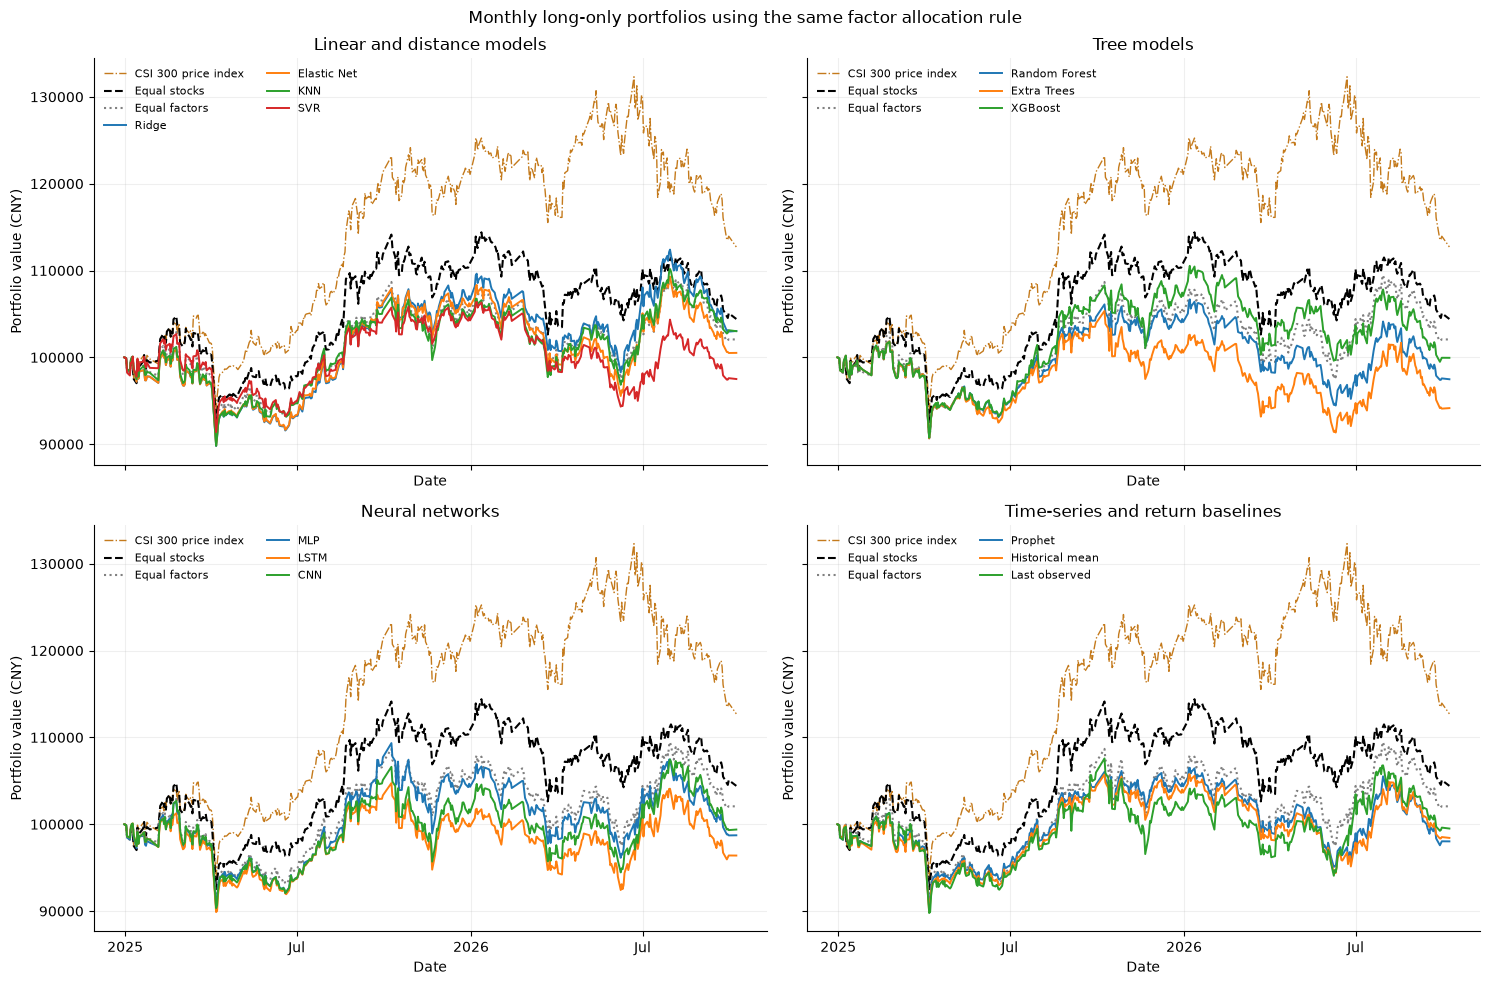

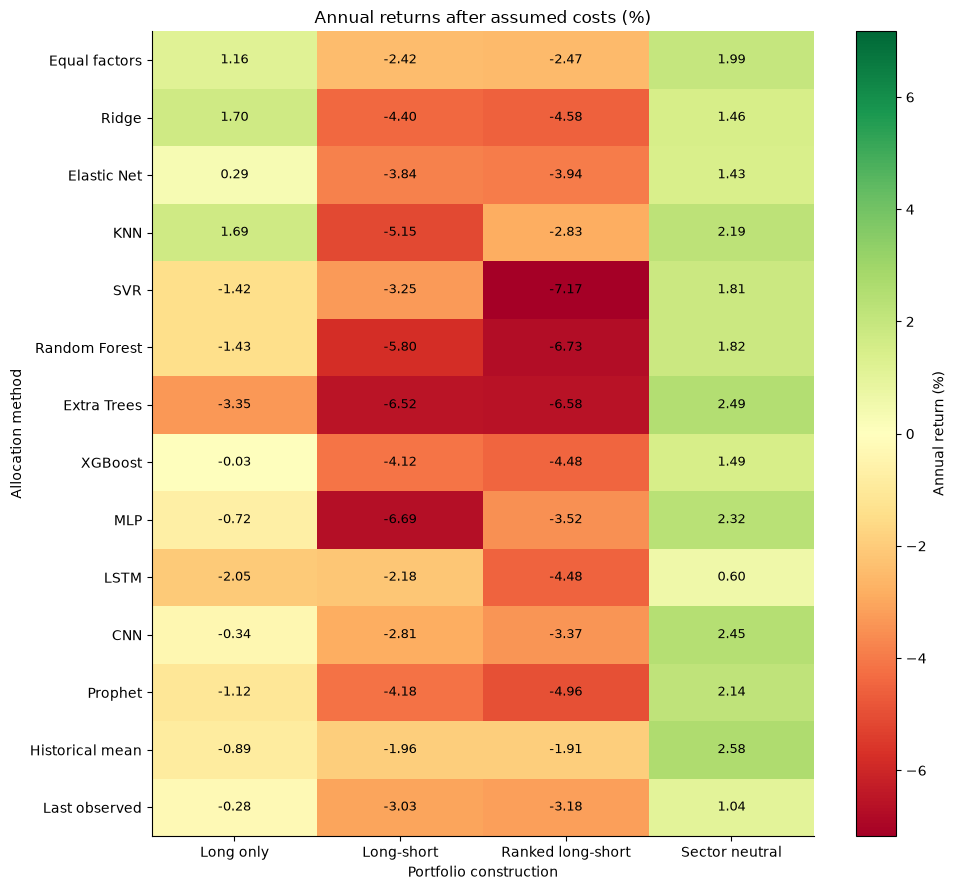

In [17]:
groups = {
    'Linear and distance models': ['Ridge', 'Elastic Net', 'KNN', 'SVR'],
    'Tree models': ['Random Forest', 'Extra Trees', 'XGBoost'],
    'Neural networks': ['MLP', 'LSTM', 'CNN'],
    'Time-series and return baselines': ['Prophet', 'Historical mean', 'Last observed']
}
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
for ax, (title, names) in zip(axes.flat, groups.items()):
    ax.plot(portfolio_values.index, portfolio_values['CSI 300 price index'], color='#c47a1c', linestyle='-.', label='CSI 300 price index', linewidth=1)
    ax.plot(portfolio_values.index, portfolio_values['Monthly equal stocks'], color='black', linestyle='--', label='Equal stocks')
    ax.plot(portfolio_values.index, portfolio_values['Long only | Equal factors'], color='gray', linestyle=':', label='Equal factors')
    for name in names:
        key = f'Long only | {name}'
        if key in portfolio_values:
            ax.plot(portfolio_values.index, portfolio_values[key], label=name, linewidth=1.4)
    ax.set(title=title, xlabel='Date', ylabel='Portfolio value (CNY)')
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8, ncol=2)
    locator = AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))
fig.suptitle('Monthly long-only portfolios using the same factor allocation rule')
fig.tight_layout()
fig.savefig(RESULTS / 'all_model_portfolios.png', dpi=160)
plt.show()

returns = pd.DataFrame({mode: {name: performance.loc[f'{mode} | {name}', 'Annual return %'] for name in ['Equal factors'] + complete_models[mode]} for mode in MODES}).reindex(['Equal factors'] + MODEL_NAMES)
fig, ax = plt.subplots(figsize=(10, 9))
limit = np.nanmax(np.abs(returns.to_numpy()))
picture = ax.imshow(returns, cmap='RdYlGn', vmin=-limit, vmax=limit, aspect='auto')
ax.set_xticks(range(len(MODES)), MODES)
ax.set_yticks(range(len(returns)), returns.index)
for row in range(len(returns)):
    for column in range(len(MODES)):
        value = returns.iloc[row, column]
        if np.isfinite(value):
            ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=9)
ax.set(title='Annual returns after assumed costs (%)', xlabel='Portfolio construction', ylabel='Allocation method')
fig.colorbar(picture, ax=ax, label='Annual return (%)')
fig.tight_layout()
fig.savefig(RESULTS / 'all_model_returns.png', dpi=160)
plt.show()

In [18]:
overlap_rows = []
for signal in test_signals:
    longs = buckets[('Long only', signal)].gt(0)
    for left, right in [('Value', 'Profitability'), ('Value', 'Momentum'), ('Profitability', 'Momentum')]:
        shared = (longs[left] & longs[right]).sum()
        overlap_rows.append({'signal': signal, 'Pair': f'{left} / {right}', 'Shared stocks': shared, 'Overlap %': shared / 5 * 100})
overlap = pd.DataFrame(overlap_rows)
overlap.to_csv(RESULTS / 'overlap.csv', index=False)
display(overlap.groupby('Pair')[['Shared stocks', 'Overlap %']].mean().round(2))

exposure_rows = []
sector_rows = []
for name, frame in weights.items():
    for signal, target in frame.iterrows():
        gross = target.abs().sum()
        sector_net = target.groupby(SECTORS).sum()
        exposure_rows.append({
            'strategy': name, 'signal': signal,
            'Gross exposure %': gross * 100,
            'Net exposure %': target.sum() * 100,
            'Largest stock %': target.abs().max() * 100,
            'Largest sector net %': sector_net.abs().max() * 100,
            'Active stocks': target.abs().gt(1e-10).sum(),
            'Cancelled gross %': max(0, 1 - gross) * 100
        })
        sector_rows.extend({'strategy': name, 'signal': signal, 'sector': sector, 'net_weight': value} for sector, value in sector_net.items())
exposures = pd.DataFrame(exposure_rows)
sector_exposures = pd.DataFrame(sector_rows)
exposures.to_csv(RESULTS / 'rebalance_exposure.csv', index=False)
sector_exposures.to_csv(RESULTS / 'sector_exposure.csv', index=False)
summary = exposures.groupby('strategy', sort=False).agg({
    'Gross exposure %': 'mean', 'Net exposure %': 'mean',
    'Largest stock %': 'max', 'Largest sector net %': 'max',
    'Active stocks': 'mean', 'Cancelled gross %': 'mean'
})
summary.columns = ['Average gross %', 'Average net %', 'Maximum stock %', 'Maximum sector net %', 'Average holdings', 'Average cancelled gross %']
summary.to_csv(RESULTS / 'exposure_summary.csv')
display(summary.round(2))

,Shared stocks,Overlap %
Pair,,
Profitability / Momentum,2.140,42.860
Value / Momentum,0.570,11.430
Value / Profitability,1.810,36.190


,Average gross %,Average net %,Maximum stock %,Maximum sector net %,Average holdings,Average cancelled gross %
strategy,,,,,,
Four-week equal factors,100.000,100.000,20.000,46.670,10.570,0.000
Monthly equal stocks,100.000,100.000,5.000,35.000,20.000,0.000
Long only | Equal factors,100.000,100.000,20.000,46.670,10.670,0.000
Long only | Ridge,100.000,100.000,20.000,50.000,10.670,0.000
Long only | Elastic Net,100.000,100.000,20.000,50.000,10.670,0.000
Long only | KNN,100.000,100.000,20.000,56.000,10.670,0.000
Long only | SVR,100.000,100.000,20.000,54.000,10.670,0.000
Long only | Random Forest,100.000,100.000,20.000,54.000,10.670,0.000
Long only | Extra Trees,100.000,100.000,20.000,52.000,10.670,0.000


The overlap table counts stocks shared by the top-five baskets. The exposure table shows the combined portfolio. A sector starts balanced in the sector-neutral version, but its weight can move as prices change before the next rebalance.

Value and Profitability shared 1.81 stocks on average out of five. Value and Momentum shared 0.57. After combining the baskets, the equal-factor long-only portfolio held about 10.7 different stocks. Its largest stock weight reached 20%. In the top/bottom long-short version, the same equal-factor rule had 69.52% average gross exposure after positions cancelled. The sector-neutral portfolios used seventeen stocks. The three companies in sectors with only one member had no position in that construction.

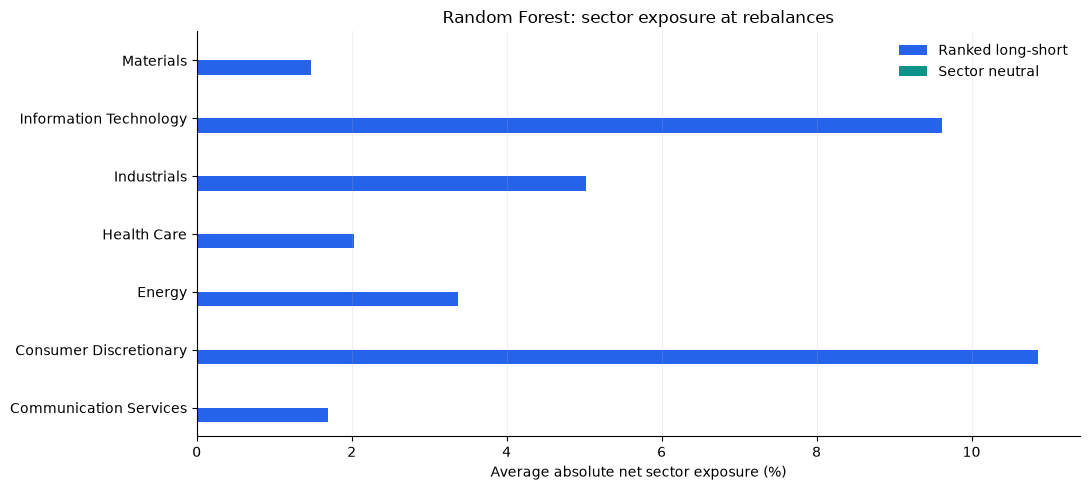

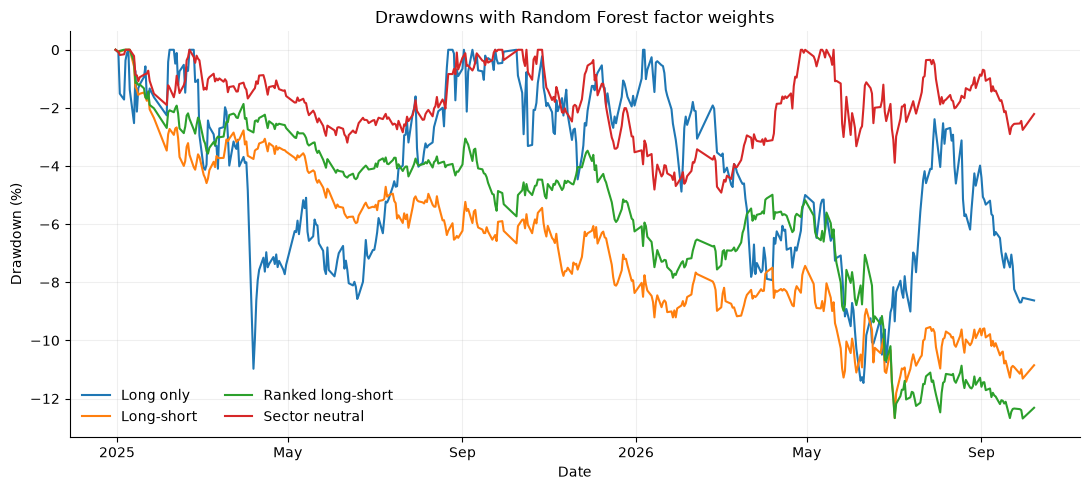

In [19]:
sector_names = [f'{mode} | Random Forest' for mode in ['Ranked long-short', 'Sector neutral'] if f'{mode} | Random Forest' in portfolio_values]
if len(sector_names) == 2:
    sector_chart = sector_exposures.loc[sector_exposures.strategy.isin(sector_names)].copy()
    sector_chart['Absolute net exposure %'] = sector_chart.net_weight.abs() * 100
    sector_chart = sector_chart.groupby(['sector', 'strategy'])['Absolute net exposure %'].mean().unstack().reindex(columns=sector_names)
    sector_chart.columns = ['Ranked long-short', 'Sector neutral']
    ax = sector_chart.plot.barh(figsize=(11, 5), color=['#2563eb', '#0d9488'])
    ax.set(title='Random Forest: sector exposure at rebalances', xlabel='Average absolute net sector exposure (%)', ylabel='')
    ax.grid(axis='x', alpha=0.2)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(RESULTS / 'sector_exposure.png', dpi=160)
    plt.show()
else:
    print('The Random Forest sector chart needs completed forecasts for both constructions.')

drawdown_names = [mode for mode in MODES if f'{mode} | Random Forest' in portfolio_values]
if drawdown_names:
    fig, ax = plt.subplots(figsize=(11, 5))
    for mode in drawdown_names:
        nav = portfolio_values[f'{mode} | Random Forest']
        ax.plot(nav.index, (nav / nav.cummax() - 1) * 100, label=mode)
    ax.set(title='Drawdowns with Random Forest factor weights', xlabel='Date', ylabel='Drawdown (%)')
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, ncol=2)
    locator = AutoDateLocator(minticks=5, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))
    fig.tight_layout()
    fig.savefig(RESULTS / 'drawdowns.png', dpi=160)
    plt.show()

A positive forecast is Up. A zero or negative forecast is Down. Accuracy counts the directions we got right. Balanced accuracy gives rising and falling outcomes equal importance. Down recall shows how many falling outcomes we found. MAE is the average size of the return error, in percentage points.

We compare forecasts with factor returns before portfolio costs. These forecasts share stocks and dates, so they are related. There are sixty-three forecasts per model and construction: three factors over twenty-one months. In the original long-only test, CNN got 49.21% of directions right, with 51.93% balanced accuracy. Always Up got 46.03% right. In the sector-neutral test, MLP reached 65.08% accuracy and 65.62% down recall. These are different baskets, so we read each result beside its own portfolio table.

In [20]:
accuracy_rows = []
for mode in MODES:
    for name in complete_models[mode] + ['Always Up']:
        reference = 'Historical mean' if name == 'Always Up' else name
        group = forecasts.loc[(forecasts['mode'] == mode) & (forecasts.model == reference)]
        actual_up = group.actual.to_numpy() > 0
        predicted_up = np.ones(len(group), dtype=bool) if name == 'Always Up' else group.prediction.to_numpy() > 0
        up_recall = predicted_up[actual_up].mean() if actual_up.any() else np.nan
        down_recall = (~predicted_up[~actual_up]).mean() if (~actual_up).any() else np.nan
        accuracy_rows.append({'Construction': mode, 'Forecast': name, 'Accuracy %': 100 * (actual_up == predicted_up).mean(), 'Balanced accuracy %': 50 * (up_recall + down_recall), 'Down recall %': 100 * down_recall, 'Predicted Up %': 100 * predicted_up.mean(), 'MAE percentage points': np.nan if name == 'Always Up' else 100 * (group.prediction - group.actual).abs().mean(), 'Forecasts': len(group)})
accuracy = pd.DataFrame(accuracy_rows).set_index(['Construction', 'Forecast'])
accuracy.to_csv(RESULTS / 'forecast_accuracy.csv')
for mode in MODES:
    print(mode)
    display(accuracy.loc[mode].round(2))

Long only


,Accuracy %,Balanced accuracy %,Down recall %,Predicted Up %,MAE percentage points,Forecasts
Forecast,,,,,,
Ridge,47.620,48.940,32.350,66.670,4.480,63
Elastic Net,47.620,48.430,38.240,60.320,5.020,63
KNN,44.440,47.010,14.710,82.540,3.570,63
SVR,44.440,44.980,38.240,57.140,3.770,63
Random Forest,39.680,42.600,5.880,87.300,3.620,63
Extra Trees,36.510,39.150,5.880,84.130,3.620,63
XGBoost,49.210,50.150,38.240,61.900,3.840,63
MLP,49.210,50.910,29.410,71.430,4.640,63
LSTM,47.620,50.960,8.820,92.060,3.870,63


Long-short


,Accuracy %,Balanced accuracy %,Down recall %,Predicted Up %,MAE percentage points,Forecasts
Forecast,,,,,,
Ridge,49.210,49.390,47.060,52.380,3.070,63
Elastic Net,50.790,51.620,41.180,60.320,3.210,63
KNN,52.380,51.060,67.650,33.330,2.360,63
SVR,46.030,45.940,47.060,49.210,2.370,63
Random Forest,34.920,33.620,50.000,34.920,2.310,63
Extra Trees,44.440,43.460,55.880,38.100,2.290,63
XGBoost,49.210,48.880,52.940,46.030,2.390,63
MLP,44.440,43.970,50.000,44.440,2.960,63
LSTM,42.860,42.490,47.060,46.030,2.290,63


Ranked long-short


,Accuracy %,Balanced accuracy %,Down recall %,Predicted Up %,MAE percentage points,Forecasts
Forecast,,,,,,
Ridge,50.790,50.760,51.520,49.210,2.580,63
Elastic Net,50.790,50.760,51.520,49.210,2.810,63
KNN,49.210,48.480,63.640,34.920,2.050,63
SVR,36.510,36.210,42.420,44.440,2.130,63
Random Forest,38.100,37.270,54.550,33.330,2.090,63
Extra Trees,39.680,38.330,66.670,22.220,2.080,63
XGBoost,47.620,47.420,51.520,46.030,2.150,63
MLP,55.560,55.000,66.670,38.100,2.300,63
LSTM,42.860,42.120,57.580,34.920,2.110,63


Sector neutral


,Accuracy %,Balanced accuracy %,Down recall %,Predicted Up %,MAE percentage points,Forecasts
Forecast,,,,,,
Ridge,58.730,58.870,50.000,58.730,1.920,63
Elastic Net,52.380,52.520,43.750,58.730,2.120,63
KNN,57.140,57.260,50.000,57.140,1.440,63
SVR,58.730,58.670,62.500,46.030,1.510,63
Random Forest,52.380,52.320,56.250,46.030,1.500,63
Extra Trees,57.140,57.010,65.620,41.270,1.470,63
XGBoost,57.140,56.960,68.750,38.100,1.550,63
MLP,65.080,65.070,65.620,49.210,1.550,63
LSTM,49.210,49.090,56.250,42.860,1.540,63


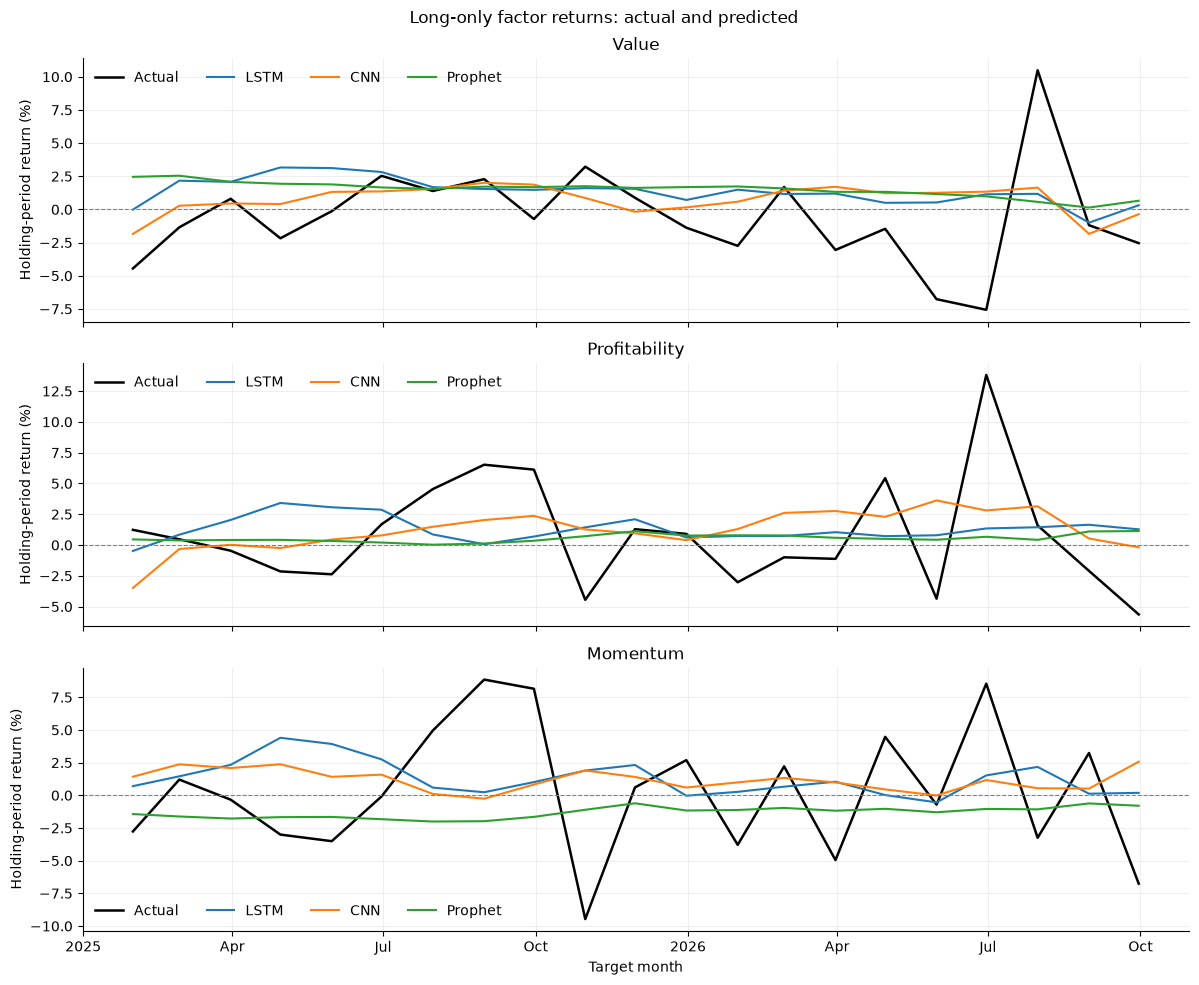

Last completed test: signal 2026-08-31, holding period 2026-09-01 to 2026-10-08.


factor,Value,Profitability,Momentum
model,,,
Ridge,-2.20% (Down),-1.44% (Down),1.61% (Up)
Elastic Net,-2.52% (Down),-3.40% (Down),-0.94% (Down)
KNN,-0.23% (Down),-0.39% (Down),-0.55% (Down)
SVR,-0.15% (Down),-0.64% (Down),-0.38% (Down)
Random Forest,0.48% (Up),0.14% (Up),0.40% (Up)
Extra Trees,0.04% (Up),0.06% (Up),0.21% (Up)
XGBoost,-0.70% (Down),1.66% (Up),-1.87% (Down)
MLP,-2.84% (Down),-4.01% (Down),-2.42% (Down)
LSTM,0.31% (Up),1.27% (Up),0.19% (Up)


In [21]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, factor in zip(axes, FACTORS):
    actual = forecasts.loc[(forecasts['mode'] == 'Long only') & (forecasts.factor == factor) & (forecasts.model == 'Historical mean')].set_index('signal').actual
    target_months = actual.index + pd.offsets.MonthEnd(1)
    ax.plot(target_months, actual * 100, color='black', label='Actual', linewidth=1.8)
    for name in ['LSTM', 'CNN', 'Prophet']:
        prediction = forecasts.loc[(forecasts['mode'] == 'Long only') & (forecasts.factor == factor) & (forecasts.model == name)].set_index('signal').prediction
        if len(prediction) == len(actual):
            ax.plot(target_months, prediction.reindex(actual.index) * 100, label=name)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set(title=factor, ylabel='Holding-period return (%)')
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, ncol=4)
locator = AutoDateLocator(minticks=4, maxticks=8)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(ConciseDateFormatter(locator))
axes[-1].set_xlabel('Target month')
fig.suptitle('Long-only factor returns: actual and predicted')
fig.tight_layout()
fig.savefig(RESULTS / 'deep_factor_predictions.png', dpi=160)
plt.show()

last_signal = test_signals[-1]
latest = forecasts.loc[(forecasts['mode'] == 'Long only') & (forecasts.signal == last_signal)].copy()
latest['Prediction'] = latest['prediction'].map(lambda value: f'{value:.2%}') + ' (' + latest.trend + ')'
latest.to_csv(RESULTS / 'last_test_predictions.csv', index=False)
print(f'Last completed test: signal {last_signal.date()}, holding period {latest.entry.iloc[0].date()} to {latest.exit.iloc[0].date()}.')
display(latest.pivot(index='model', columns='factor', values='Prediction').reindex(index=MODEL_NAMES, columns=FACTORS))

The last prediction table is a completed historical test, not today's forecast. We can compare the forecast with what happened over that holding period.

For the last holding period, from 1 September to 8 October 2026, the long-only Value basket returned -2.54%, Profitability returned -5.64%, and Momentum returned -6.76% before costs. The borrowing comparison also changed the result. For equal-factor top/bottom long-short, annual return was -1.40% with no borrowing charge, -2.42% with a 3% charge, and -3.43% with a 6% charge. The holdings stayed the same; the cost assumption changed.

In [22]:
sensitivity_rows = []
for mode in MODES[1:]:
    for model_name in ['Equal factors'] + complete_models[mode]:
        name = f'{mode} | {model_name}'
        for rate in [0.0, 0.03, 0.06]:
            if rate == BORROW_RATE:
                result = performance.loc[name]
            else:
                nav, log, _ = backtest(prices, monthly_schedule, weights[name], INITIAL_VALUE, TRADING_COST, rate)
                result = performance_row(nav, log)
            sensitivity_rows.append({'Construction': mode, 'Model': model_name, 'Annual borrowing assumption %': rate * 100, 'Annual return %': result['Annual return %'], 'Borrowing costs CNY': result['Borrowing costs CNY']})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(RESULTS / 'borrowing_sensitivity.csv', index=False)
for mode in MODES[1:]:
    print(mode)
    display(sensitivity.loc[sensitivity.Construction == mode].pivot(index='Model', columns='Annual borrowing assumption %', values='Annual return %').reindex(['Equal factors'] + complete_models[mode]).round(2))

Long-short


Annual borrowing assumption %,0.000,3.000,6.000
Model,,,
Equal factors,-1.400,-2.420,-3.430
Ridge,-3.350,-4.400,-5.440
Elastic Net,-2.780,-3.840,-4.900
KNN,-4.090,-5.150,-6.200
SVR,-2.160,-3.250,-4.340
Random Forest,-4.730,-5.800,-6.860
Extra Trees,-5.470,-6.520,-7.570
XGBoost,-3.050,-4.120,-5.180
MLP,-5.650,-6.690,-7.730


Ranked long-short


Annual borrowing assumption %,0.000,3.000,6.000
Model,,,
Equal factors,-1.600,-2.470,-3.320
Ridge,-3.720,-4.580,-5.440
Elastic Net,-3.050,-3.940,-4.820
KNN,-1.930,-2.830,-3.730
SVR,-6.320,-7.170,-8.020
Random Forest,-5.860,-6.730,-7.600
Extra Trees,-5.710,-6.580,-7.460
XGBoost,-3.560,-4.480,-5.400
MLP,-2.630,-3.520,-4.410


Sector neutral


Annual borrowing assumption %,0.000,3.000,6.000
Model,,,
Equal factors,3.120,1.990,0.870
Ridge,2.630,1.460,0.300
Elastic Net,2.600,1.430,0.270
KNN,3.410,2.190,0.990
SVR,3.000,1.810,0.630
Random Forest,3.040,1.820,0.610
Extra Trees,3.710,2.490,1.270
XGBoost,2.680,1.490,0.310
MLP,3.500,2.320,1.150


We completed the main factor comparison. We also tested different accounting measures, input periods and random seeds. The following sections show the results of these comparisons.

We also compare the accounting measures in the proposal. We change one factor at a time and keep the other two unchanged. Value is compared with earnings yield and book-to-market. Profitability is compared with EBIT divided by book equity. We also compare average and year-end invested capital. Momentum is compared with the ordinary price return before dividing by volatility. Every version uses the same top-five rule and equal weights between factors. These are factor-definition comparisons, not new model searches.

,Annual return %,Volatility %,Sharpe (0% reference),Max drawdown %,Final value CNY
Definition,,,,,
Main EBIT factors,1.160,10.170,0.260,-11.790,"102,059.050"
Value: earnings yield,2.290,10.200,0.340,-11.850,"104,083.150"
Value: book to market,3.210,10.870,0.410,-12.870,"105,743.910"
Profitability: EBIT to equity,2.480,10.990,0.330,-11.710,"104,435.680"
Profitability: year-end capital,1.270,10.070,0.270,-11.590,"102,265.050"
Momentum: ordinary return,-0.330,10.950,0.120,-11.790,"99,408.490"


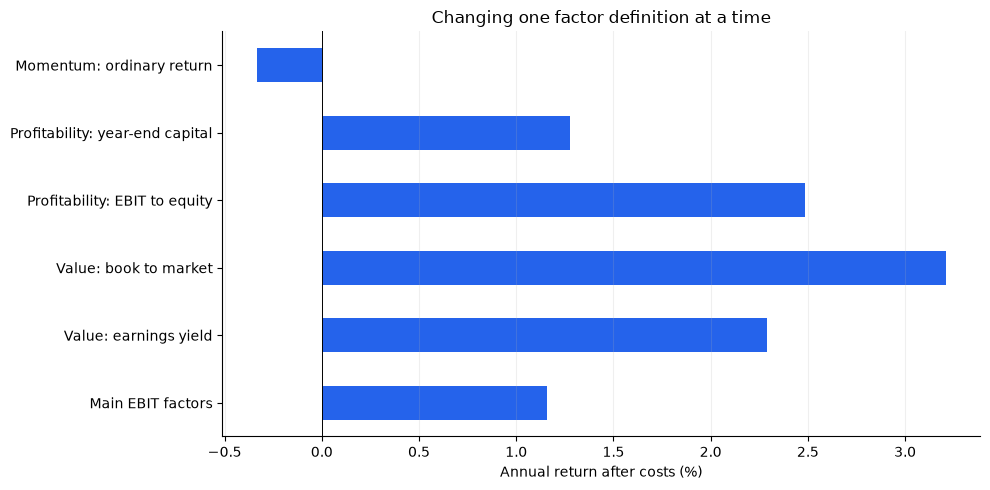

In [23]:
DEFINITION_CHANGES = {
    'Main EBIT factors': {},
    'Value: earnings yield': {'Value': 'Earnings yield'},
    'Value: book to market': {'Value': 'Book to market'},
    'Profitability: EBIT to equity': {'Profitability': 'EBIT to book equity'},
    'Profitability: year-end capital': {'Profitability': 'EBIT to year-end capital'},
    'Momentum: ordinary return': {'Momentum': 'Ordinary momentum'}
}

definition_rows = []
definition_values = []
definition_weights = []
definition_trades = []
for name, changes in DEFINITION_CHANGES.items():
    rows = {}
    for signal in test_signals:
        details = score_details(signal)
        scores = details[FACTORS].copy()
        for factor, replacement in changes.items():
            scores[factor] = details[replacement]
        rows[signal] = make_buckets(scores, 'Long only').mean(axis=1)
    target = pd.DataFrame(rows).T
    nav, log, exposure = backtest(prices, monthly_schedule, target, INITIAL_VALUE, TRADING_COST, 0.0)
    definition_rows.append({'Definition': name, **performance_row(nav, log)})
    definition_values.append(nav.rename(name))
    definition_weights.append(target.rename_axis('signal').reset_index().assign(Definition=name))
    definition_trades.append(log.assign(Definition=name))
definition_performance = pd.DataFrame(definition_rows).set_index('Definition')
definition_performance.to_csv(RESULTS / 'factor_definition_performance.csv')
pd.concat(definition_values, axis=1).to_csv(RESULTS / 'factor_definition_values.csv', index_label='date')
pd.concat(definition_weights, ignore_index=True).to_csv(RESULTS / 'factor_definition_weights.csv', index=False)
pd.concat(definition_trades, ignore_index=True).to_csv(RESULTS / 'factor_definition_trades.csv', index=False)
display(definition_performance[shown].round(2))
ax = definition_performance['Annual return %'].plot.barh(figsize=(10, 5), color='#2563eb')
ax.set(xlabel='Annual return after costs (%)', ylabel='', title='Changing one factor definition at a time')
ax.axvline(0, color='black', linewidth=0.7)
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS / 'factor_definitions.png', dpi=150)
plt.show()

The main EBIT factors returned 1.16% a year with equal factor weights. Changing only Value to earnings yield gave 2.29%, while book-to-market gave 3.21%. Changing Profitability to EBIT divided by book equity gave 2.48%. Using year-end invested capital gave 1.27%, compared with the average-capital measure in our main test. Ordinary momentum gave -0.33%. We can see that the accounting measure and the momentum definition both change the stocks we hold and the return we get. All these figures include the same trading-cost rule.

We change the cost charged on every purchase and sale to 0%, 0.10% and 0.30%. The trades and forecasts stay the same. This lets us see how much each strategy depends on cheap trading. These flat charges are assumptions, not an estimate of every market fee.

In [24]:
COST_RATES = [0.0, 0.001, 0.003]
COST_MODELS = ['Equal factors'] + LEARNED_MODELS

cost_rows = []
for model in COST_MODELS:
    key = f'Long only | {model}'
    for rate in COST_RATES:
        nav, log, exposure = backtest(prices, monthly_schedule, weights[key], INITIAL_VALUE, rate, 0.0)
        cost_rows.append({'Model': model, 'Cost per traded amount %': rate * 100, **performance_row(nav, log)})
cost_comparison = pd.DataFrame(cost_rows)
cost_comparison.to_csv(RESULTS / 'trading_cost_sensitivity.csv', index=False)
display(cost_comparison.pivot(index='Model', columns='Cost per traded amount %', values='Annual return %').reindex(COST_MODELS).round(2))

Cost per traded amount %,0.000,0.100,0.300
Model,,,
Equal factors,1.510,1.160,0.460
Ridge,2.220,1.700,0.690
Elastic Net,0.820,0.290,-0.760
KNN,2.200,1.690,0.680
SVR,-1.010,-1.420,-2.230
Random Forest,-0.950,-1.430,-2.380
Extra Trees,-2.850,-3.350,-4.330
XGBoost,0.530,-0.030,-1.140
MLP,-0.150,-0.720,-1.850


Trading costs made a clear difference. The equal-factor long-only portfolio returned 1.51% a year with no trading charge. This became 1.16% at 0.10% per traded amount and 0.46% at 0.30%. Ridge changed from 2.22% to 0.69% across the same cost range. We used the same forecasts and target weights in each case. The larger charge reduced the money left in the portfolio.

We compared four input settings. The first keeps the original one-, four- and thirteen-week returns with thirteen weeks for volatility and correlation. The other settings change the return windows to two, eight and twenty-six weeks, the risk window to twenty-six weeks, or both. These are observed weeks in our shared price series. The eight-row model sequence stays the same. We also keep the stock scores, factor baskets, next-month targets, allocation rule and costs unchanged.

We use twelve earlier validation signals, from 30 November 2023 to 31 October 2024, to choose a window setting for each model. All their target returns finish before the first original test signal on 31 December 2024. At each validation signal, the model only sees returns already completed then. We choose the setting with the lowest average absolute forecast error across the three factors. If there is an exact tie, we keep the earlier setting in the table, with the original first.

We compare the selected settings over twenty-one test months. This period has been used during our research, so we treat the results as a sensitivity comparison on an existing sample. We do not choose the window or seed using its test return. Prophet uses monthly return history rather than these weekly features, so it has one result and no window choice.

In [25]:
WINDOWS = {
    'Original': ((1, 4, 13), 13),
    'Longer returns': ((2, 8, 26), 13),
    'Longer risk': ((1, 4, 13), 26),
    'Both longer': ((2, 8, 26), 26)
}
VALIDATION_MONTHS = 12
MIN_VALIDATION_TRAINING = 36
BASE_SEED = 42

validation_signals = label_end.index[label_end.notna() & label_end.lt(FIRST_SIGNAL)][-VALIDATION_MONTHS:]
if len(validation_signals) != VALIDATION_MONTHS or not label_end.loc[validation_signals].lt(FIRST_SIGNAL).all():
    raise ValueError('Validation targets must finish before the first test signal.')
validation_schedule = pd.DataFrame({'signal': validation_signals, 'entry': [next_close(d) for d in validation_signals], 'exit': label_end.loc[validation_signals].to_numpy()})
validation_schedule.to_csv(RESULTS / 'validation_schedule.csv', index=False)
window_table = pd.DataFrame([{'Setting': name, 'Return weeks': ', '.join(map(str, windows)), 'Risk weeks': risk, 'Sequence weeks': LOOKBACK, 'Inputs per week': 13} for name, (windows, risk) in WINDOWS.items()])
window_table.to_csv(RESULTS / 'window_settings.csv', index=False)
window_sequences = {'Original': sequence_inputs['Long only']}
window_input_rows = []
for setting, (return_windows, risk_window) in WINDOWS.items():
    windows = []
    for signal in month_ends:
        weeks = weekly.loc[:signal].tail(LOOKBACK).index
        basket = buckets[('Long only', signal)]
        frame = pd.DataFrame([model_inputs(week, basket, return_windows, risk_window) for week in weeks], index=weeks)
        if frame.shape != (8, 13) or not np.isfinite(frame.to_numpy()).all() or weeks[-1] > signal:
            raise ValueError('Check the feature window and its dates.')
        windows.append(frame.to_numpy())
        window_input_rows.append(frame.rename_axis('week').reset_index().assign(setting=setting, signal=signal))
    window_sequences[setting] = np.stack(windows)
if not np.allclose(window_sequences['Original'], sequence_inputs['Long only']):
    raise ValueError('The original feature settings changed.')
pd.concat(window_input_rows, ignore_index=True).to_csv(RESULTS / 'window_sequence_inputs.csv', index=False)
display(window_table)
display(validation_schedule.iloc[[0, -1]])

,Setting,Return weeks,Risk weeks,Sequence weeks,Inputs per week
0,Original,"1, 4, 13",13,8,13
1,Longer returns,"2, 8, 26",13,8,13
2,Longer risk,"1, 4, 13",26,8,13
3,Both longer,"2, 8, 26",26,8,13


,signal,entry,exit
0,2023-11-30,2023-12-01,2024-01-02
11,2024-10-31,2024-11-01,2024-12-02


In [26]:
comparison_fits = []
comparison_warnings = []
comparison_audits = []
comparison_losses = []

def predict_setting(name, setting, seed, signal, stage):
    eligible = label_end.lt(signal) & targets['Long only'].notna().all(axis=1)
    train_x = window_sequences[setting][eligible.to_numpy()]
    train_y = targets['Long only'].loc[eligible]
    test_x = window_sequences[setting][[month_ends.get_loc(signal)]]
    required = MIN_VALIDATION_TRAINING if stage == 'Validation' else 60
    if len(train_y) < required or not label_end.loc[eligible].lt(signal).all():
        raise ValueError('Training labels must end before the signal.')
    key = {'stage': stage, 'setting': setting, 'seed': seed, 'model': name, 'signal': signal}
    comparison_audits.append({**key, 'training_months': len(train_y), 'first_training_signal': train_y.index.min(), 'latest_training_exit': label_end.loc[eligible].max(), 'last_input_week': weekly.loc[:signal].index[-1], 'features': train_x.shape[1] * train_x.shape[2]})
    try:
        with warnings.catch_warnings(record=True) as caught, contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            warnings.simplefilter('always')
            if name in ['LSTM', 'CNN']:
                model_class = SmallLSTM if name == 'LSTM' else SmallCNN
                predicted, losses = fit_deep(model_class, train_x, train_y.to_numpy(), test_x, seed)
                comparison_losses.extend({**key, 'epoch': epoch + 1, 'training_mse_scaled': value} for epoch, value in enumerate(losses))
            elif name == 'Prophet':
                predicted = fit_prophet(train_y, signal + pd.offsets.MonthEnd(1), seed)
            else:
                model = make_models(seed)[name]
                model.fit(train_x.reshape(len(train_x), -1), train_y.to_numpy())
                predicted = np.asarray(model.predict(test_x.reshape(1, -1))).reshape(-1)
        comparison_warnings.extend({**key, 'category': item.category.__name__, 'message': str(item.message)} for item in caught)
        if np.asarray(predicted).shape != (3,) or not np.isfinite(predicted).all():
            raise ValueError('Each model must produce three finite forecasts.')
        comparison_fits.append({**key, 'status': 'Completed', 'notices': len(caught)})
    except Exception as error:
        comparison_fits.append({**key, 'status': 'Failed', 'notices': 0, 'message': str(error)})
        pd.DataFrame(comparison_fits).to_csv(RESULTS / 'comparison_fit_status.csv', index=False)
        raise
    return [{**key, 'factor': factor, 'prediction': float(value), 'actual': float(targets['Long only'].loc[signal, factor]), 'entry': next_close(signal), 'exit': label_end.loc[signal]} for factor, value in zip(FACTORS, predicted)]

def forecast_metrics(frame):
    up = frame.actual.to_numpy() > 0
    predicted_up = frame.prediction.to_numpy() > 0
    up_recall = predicted_up[up].mean() if up.any() else np.nan
    down_recall = (~predicted_up[~up]).mean() if (~up).any() else np.nan
    return {'MAE pp': 100 * (frame.prediction - frame.actual).abs().mean(), 'Accuracy %': 100 * (up == predicted_up).mean(), 'Balanced accuracy %': 50 * (up_recall + down_recall), 'Down recall %': 100 * down_recall, 'Predicted Up %': 100 * predicted_up.mean(), 'Forecasts': len(frame)}

validation_rows = []
for setting in WINDOWS:
    for name in LEARNED_MODELS:
        if name == 'Prophet' and setting != 'Original':
            continue
        for signal in validation_signals:
            validation_rows.extend(predict_setting(name, setting, BASE_SEED, signal, 'Validation'))
    print(f'Validation finished: {setting}')
validation_predictions = pd.DataFrame(validation_rows)
validation_predictions.to_csv(RESULTS / 'validation_predictions.csv', index=False)
validation_metrics = pd.DataFrame([{'Model': name, 'Setting': setting, **forecast_metrics(group)} for (name, setting), group in validation_predictions.groupby(['model', 'setting'], sort=False)])
validation_metrics['Order'] = validation_metrics.Setting.map({name: i for i, name in enumerate(WINDOWS)})
selection = validation_metrics.sort_values(['Model', 'MAE pp', 'Order'], kind='stable').drop_duplicates('Model').set_index('Model').reindex(LEARNED_MODELS).drop(columns='Order')
selection = selection.rename(columns={'MAE pp': 'Validation MAE pp'})
validation_metrics.drop(columns='Order').to_csv(RESULTS / 'window_validation_metrics.csv', index=False)
selection.to_csv(RESULTS / 'selected_windows.csv')
display(validation_metrics.pivot(index='Model', columns='Setting', values='MAE pp').reindex(index=LEARNED_MODELS, columns=WINDOWS).round(3))
display(selection[['Setting', 'Validation MAE pp']].round(3))

Validation finished: Original


Validation finished: Longer returns


Validation finished: Longer risk


Validation finished: Both longer


Setting,Original,Longer returns,Longer risk,Both longer
Model,,,,
Ridge,6.584,7.149,6.825,6.996
Elastic Net,7.616,7.844,7.194,7.602
KNN,6.434,6.390,6.284,6.288
SVR,6.270,6.396,6.309,6.359
Random Forest,6.194,6.318,6.307,6.407
Extra Trees,6.046,6.361,6.079,6.469
XGBoost,6.487,6.476,6.517,6.846
MLP,7.845,8.363,6.586,7.472
LSTM,6.278,6.212,6.266,6.107


,Setting,Validation MAE pp
Model,,
Ridge,Original,6.584
Elastic Net,Longer risk,7.194
KNN,Longer risk,6.284
SVR,Original,6.270
Random Forest,Original,6.194
Extra Trees,Original,6.046
XGBoost,Longer returns,6.476
MLP,Longer risk,6.586
LSTM,Both longer,6.107


The earlier validation period chose the original windows for Ridge, SVR, Random Forest and Extra Trees. It chose the longer risk window for Elastic Net, KNN and MLP. XGBoost used the longer return windows. LSTM and CNN used both longer return and risk windows. Prophet kept its separate monthly-history method. We made these choices from forecast error in the twelve earlier months, not from the later portfolio returns.

In [27]:
test_rows = []
original_predictions = forecasts.loc[(forecasts['mode'] == 'Long only') & forecasts.model.isin(LEARNED_MODELS)].copy()
original_predictions = original_predictions.drop(columns=['mode', 'trend']).assign(stage='Test', setting='Original', seed=BASE_SEED)
test_rows.extend(original_predictions.to_dict('records'))
for setting in list(WINDOWS)[1:]:
    for name in LEARNED_MODELS:
        if name == 'Prophet':
            continue
        for signal in test_signals:
            test_rows.extend(predict_setting(name, setting, BASE_SEED, signal, 'Test'))
    print(f'Test finished: {setting}')
window_predictions = pd.DataFrame(test_rows)
window_predictions.to_csv(RESULTS / 'window_test_predictions.csv', index=False)
window_results = []
window_navs = []
window_trades = []
window_weights = []
window_factor_weights = []

def allocation_from_forecasts(frame):
    target_rows = {}
    factor_rows = []
    for signal, group in frame.groupby('signal', sort=True):
        predicted = group.set_index('factor').prediction.reindex(FACTORS)
        ranking = predicted.sort_values(ascending=False, kind='stable').index
        factor_weight = pd.Series([0.5, 0.3, 0.2], index=ranking).reindex(FACTORS)
        target_rows[signal] = buckets[('Long only', signal)].dot(factor_weight)
        factor_rows.append({'signal': signal, **factor_weight.to_dict()})
    return pd.DataFrame(target_rows).T, pd.DataFrame(factor_rows)

for (setting, name, seed), group in window_predictions.groupby(['setting', 'model', 'seed'], sort=False):
    target, factor_weight = allocation_from_forecasts(group)
    if not target.index.equals(test_signals):
        raise ValueError('All window comparisons must use the same test dates.')
    nav, log, exposure = backtest(prices, monthly_schedule, target, INITIAL_VALUE, TRADING_COST, BORROW_RATE)
    key = {'Setting': setting, 'Model': name, 'Seed': seed}
    window_results.append({**key, 'Chosen by validation': selection.loc[name, 'Setting'] == setting, **forecast_metrics(group), **performance_row(nav, log)})
    window_navs.append(nav.rename_axis('date').reset_index().assign(**key))
    window_trades.append(log.assign(**key))
    window_weights.append(target.rename_axis('signal').reset_index().assign(**key))
    window_factor_weights.append(factor_weight.assign(**key))
window_performance = pd.DataFrame(window_results)
window_performance.to_csv(RESULTS / 'window_test_performance.csv', index=False)
pd.concat(window_navs, ignore_index=True).to_csv(RESULTS / 'window_portfolio_values.csv', index=False)
pd.concat(window_trades, ignore_index=True).to_csv(RESULTS / 'window_trading_costs.csv', index=False)
pd.concat(window_weights, ignore_index=True).to_csv(RESULTS / 'window_stock_weights.csv', index=False)
pd.concat(window_factor_weights, ignore_index=True).to_csv(RESULTS / 'window_factor_weights.csv', index=False)
selected_performance = window_performance.loc[window_performance['Chosen by validation']].set_index('Model').reindex(LEARNED_MODELS)
selected_performance.to_csv(RESULTS / 'selected_window_performance.csv')
display(selected_performance[['Setting', 'MAE pp', 'Accuracy %', 'Annual return %', 'Max drawdown %']].round(3))
display(window_performance.pivot(index='Model', columns='Setting', values='Annual return %').reindex(index=LEARNED_MODELS, columns=WINDOWS).round(2))

Test finished: Longer returns


Test finished: Longer risk


Test finished: Both longer


,Setting,MAE pp,Accuracy %,Annual return %,Max drawdown %
Model,,,,,
Ridge,Original,4.484,47.619,1.703,-11.001
Elastic Net,Longer risk,5.493,33.333,2.652,-11.081
KNN,Longer risk,3.845,47.619,0.466,-11.237
SVR,Original,3.771,44.444,-1.418,-11.335
Random Forest,Original,3.621,39.683,-1.433,-11.463
Extra Trees,Original,3.622,36.508,-3.347,-13.291
XGBoost,Longer returns,3.595,46.032,2.754,-10.918
MLP,Longer risk,4.806,47.619,-1.045,-11.088
LSTM,Both longer,3.960,42.857,0.431,-11.523


Setting,Original,Longer returns,Longer risk,Both longer
Model,,,,
Ridge,1.700,0.250,1.550,0.500
Elastic Net,0.290,1.480,2.650,1.820
KNN,1.690,1.910,0.470,-0.570
SVR,-1.420,0.160,-1.220,0.040
Random Forest,-1.430,0.780,2.240,0.530
Extra Trees,-3.350,-2.020,-3.710,1.810
XGBoost,-0.030,2.750,-0.890,0.180
MLP,-0.720,2.740,-1.050,0.220
LSTM,-2.050,-4.010,-1.940,0.430


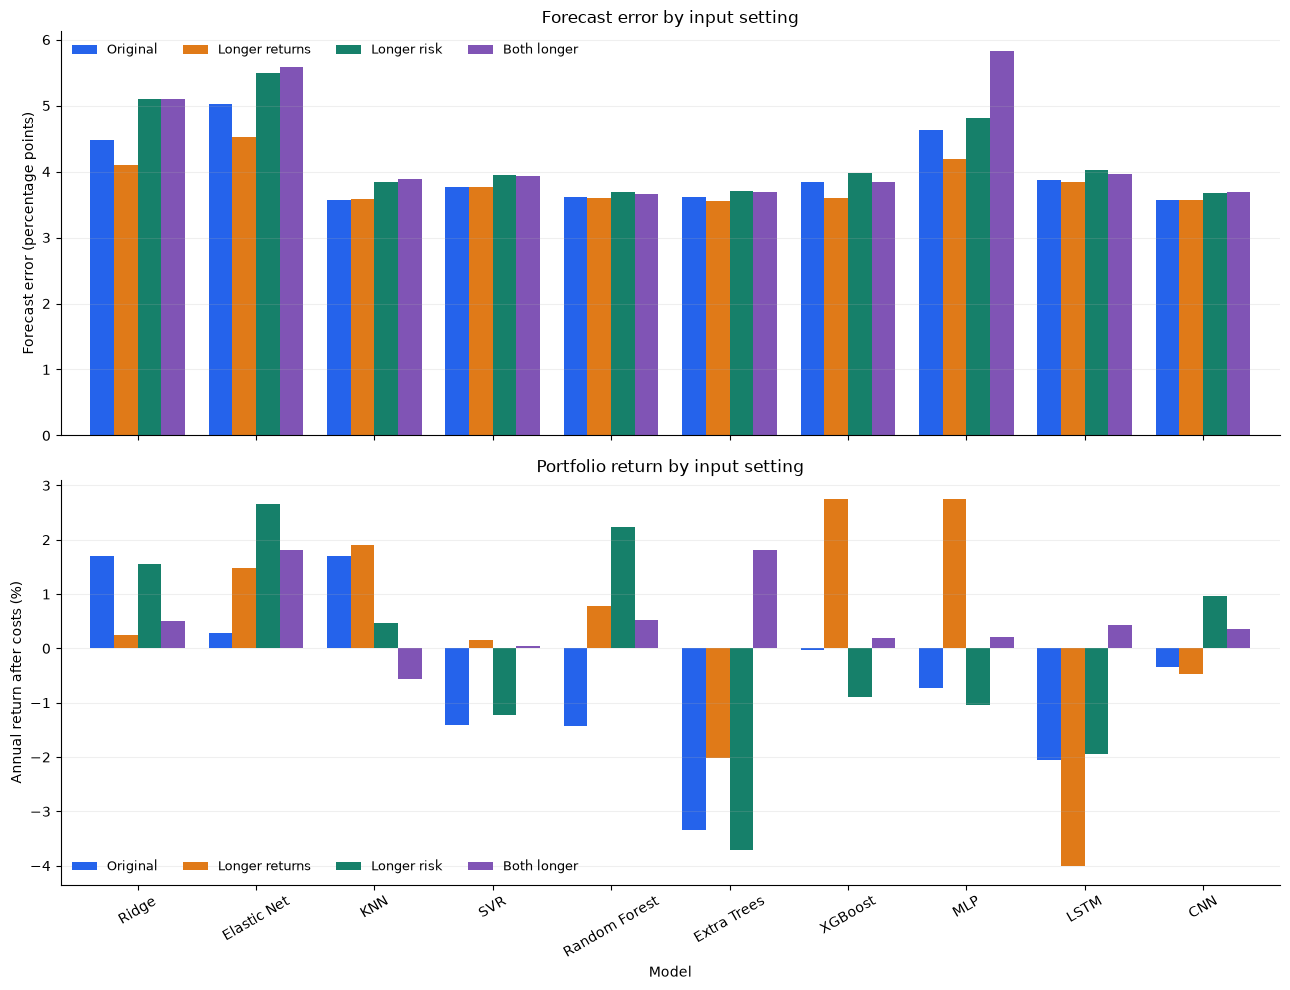

In [28]:
WINDOW_COLORS = ['#2563eb', '#e07a18', '#16806a', '#8054b5']

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
for metric, ax in zip(['MAE pp', 'Annual return %'], axes):
    table = window_performance.loc[window_performance.Model != 'Prophet'].pivot(index='Model', columns='Setting', values=metric).reindex(index=[name for name in LEARNED_MODELS if name != 'Prophet'], columns=WINDOWS)
    table.plot.bar(ax=ax, color=WINDOW_COLORS, width=0.8)
    ax.set(ylabel='Forecast error (percentage points)' if metric == 'MAE pp' else 'Annual return after costs (%)', xlabel='', title='Forecast error by input setting' if metric == 'MAE pp' else 'Portfolio return by input setting')
    ax.grid(axis='y', alpha=0.2)
    ax.legend(frameon=False, ncol=4, fontsize=9)
axes[-1].tick_params(axis='x', rotation=30)
axes[-1].set_xlabel('Model')
fig.tight_layout()
fig.savefig(RESULTS / 'window_comparison.png', dpi=150)
plt.show()

With the windows chosen from validation, XGBoost returned 2.75% a year after costs. Elastic Net returned 2.65%. The equal-factor and equal-stock comparisons stayed at 1.16% and 2.47%. LSTM returned 0.43% and CNN returned 0.35%. CNN got 55.56% of factor directions right with its selected windows. The table shows that a window change can affect forecast error and portfolio return in different ways. These are results for the same twenty-one test months.

We repeat Random Forest, Extra Trees, XGBoost, MLP, LSTM and CNN using seeds 42, 7 and 123. Each model keeps the window chosen in the earlier validation period. We keep the dates and all other settings fixed. Ridge, KNN and SVR are deterministic here. Elastic Net uses cyclic updates, so changing its seed would not create a new fit. Prophet is used here as a fitted trend model without posterior sampling; it is not part of this random-initialisation comparison.

The range across three seeds describes these three runs. It is not a confidence interval or three independent market histories. Neural-network results can also differ across software versions or machines, even with the same seed. The library version table records the setup used for this run.

Seed comparison finished: Random Forest


Seed comparison finished: Extra Trees


Seed comparison finished: XGBoost


Seed comparison finished: MLP


Seed comparison finished: LSTM


Seed comparison finished: CNN


,Model,Setting,Seed,MAE pp,Accuracy %,Annual return %,Max drawdown %
0,Random Forest,Original,42,3.621,39.683,-1.433,-11.463
1,Random Forest,Original,7,3.714,42.857,0.137,-11.121
2,Random Forest,Original,123,3.711,38.095,-2.987,-13.419
3,Extra Trees,Original,42,3.622,36.508,-3.347,-13.291
4,Extra Trees,Original,7,3.554,38.095,-1.322,-10.976
5,Extra Trees,Original,123,3.548,38.095,-2.279,-12.656
6,XGBoost,Longer returns,42,3.595,46.032,2.754,-10.918
7,XGBoost,Longer returns,7,3.758,49.206,1.845,-10.918
8,XGBoost,Longer returns,123,3.681,50.794,2.120,-10.997
9,MLP,Longer risk,42,4.806,47.619,-1.045,-11.088


,Mean annual return %,Minimum annual return %,Maximum annual return %,Mean accuracy %,Minimum MAE pp,Maximum MAE pp
Model,,,,,,
Random Forest,-1.428,-2.987,0.137,40.212,3.621,3.714
Extra Trees,-2.316,-3.347,-1.322,37.566,3.548,3.622
XGBoost,2.240,1.845,2.754,48.677,3.595,3.758
MLP,-0.225,-1.045,1.170,37.566,4.806,5.314
LSTM,0.232,-0.023,0.431,46.032,3.512,3.960
CNN,0.539,0.351,0.723,49.206,3.625,3.698


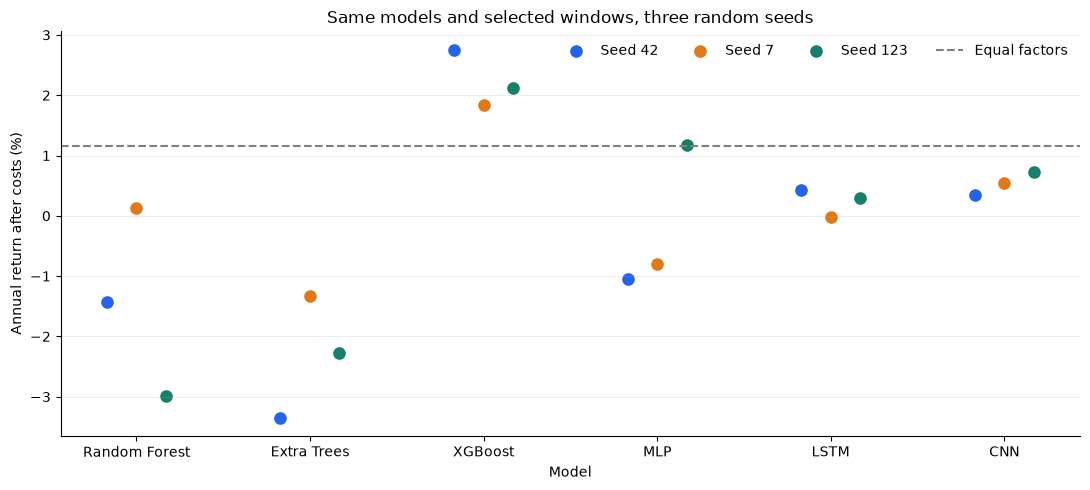

In [29]:
SEEDS = [42, 7, 123]
SEED_MODELS = ['Random Forest', 'Extra Trees', 'XGBoost', 'MLP', 'LSTM', 'CNN']

seed_rows = []
for name in SEED_MODELS:
    setting = selection.loc[name, 'Setting']
    reference = window_predictions.loc[(window_predictions.model == name) & (window_predictions.setting == setting)].copy()
    seed_rows.extend(reference.assign(stage='Seed comparison').to_dict('records'))
    for seed in SEEDS[1:]:
        for signal in test_signals:
            seed_rows.extend(predict_setting(name, setting, seed, signal, 'Seed comparison'))
    print(f'Seed comparison finished: {name}')
seed_predictions = pd.DataFrame(seed_rows)
seed_predictions.to_csv(RESULTS / 'seed_predictions.csv', index=False)
seed_results = []
seed_navs = []
seed_trade_rows = []
seed_weight_rows = []
seed_factor_rows = []
for (name, setting, seed), group in seed_predictions.groupby(['model', 'setting', 'seed'], sort=False):
    target, factor_weight = allocation_from_forecasts(group)
    nav, log, exposure = backtest(prices, monthly_schedule, target, INITIAL_VALUE, TRADING_COST, BORROW_RATE)
    key = {'Model': name, 'Setting': setting, 'Seed': seed}
    seed_results.append({**key, **forecast_metrics(group), **performance_row(nav, log)})
    seed_navs.append(nav.rename_axis('date').reset_index().assign(**key))
    seed_trade_rows.append(log.assign(**key))
    seed_weight_rows.append(target.rename_axis('signal').reset_index().assign(**key))
    seed_factor_rows.append(factor_weight.assign(**key))
seed_performance = pd.DataFrame(seed_results)
seed_performance.to_csv(RESULTS / 'seed_performance.csv', index=False)
pd.concat(seed_navs, ignore_index=True).to_csv(RESULTS / 'seed_portfolio_values.csv', index=False)
pd.concat(seed_trade_rows, ignore_index=True).to_csv(RESULTS / 'seed_trading_costs.csv', index=False)
pd.concat(seed_weight_rows, ignore_index=True).to_csv(RESULTS / 'seed_stock_weights.csv', index=False)
pd.concat(seed_factor_rows, ignore_index=True).to_csv(RESULTS / 'seed_factor_weights.csv', index=False)
seed_summary = seed_performance.groupby('Model').agg(Mean_return=('Annual return %', 'mean'), Minimum_return=('Annual return %', 'min'), Maximum_return=('Annual return %', 'max'), Mean_accuracy=('Accuracy %', 'mean'), Minimum_MAE=('MAE pp', 'min'), Maximum_MAE=('MAE pp', 'max')).reindex(SEED_MODELS)
seed_summary.columns = ['Mean annual return %', 'Minimum annual return %', 'Maximum annual return %', 'Mean accuracy %', 'Minimum MAE pp', 'Maximum MAE pp']
seed_summary.to_csv(RESULTS / 'seed_summary.csv')
display(seed_performance[['Model', 'Setting', 'Seed', 'MAE pp', 'Accuracy %', 'Annual return %', 'Max drawdown %']].round(3))
display(seed_summary.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
for seed, color, offset in zip(SEEDS, ['#2563eb', '#e07a18', '#16806a'], [-0.17, 0, 0.17]):
    values = seed_performance.loc[seed_performance.Seed == seed].set_index('Model').reindex(SEED_MODELS)
    ax.scatter(np.arange(len(SEED_MODELS)) + offset, values['Annual return %'], label=f'Seed {seed}', s=65, color=color)
ax.axhline(performance.loc['Long only | Equal factors', 'Annual return %'], color='gray', linestyle='--', label='Equal factors')
ax.set_xticks(range(len(SEED_MODELS)), SEED_MODELS)
ax.set(title='Same models and selected windows, three random seeds', xlabel='Model', ylabel='Annual return after costs (%)')
ax.grid(axis='y', alpha=0.2)
ax.legend(frameon=False, ncol=4)
fig.tight_layout()
fig.savefig(RESULTS / 'seed_comparison.png', dpi=150)
plt.show()

XGBoost returned between 1.85% and 2.75% a year across the three seeds, with an average of 2.24%. Random Forest ranged from -2.99% to 0.14%. For the deep-learning models, LSTM ranged from -0.02% to 0.43%, and CNN ranged from 0.35% to 0.72%. We can see how much the random choices changed the result while the data, window setting and portfolio rules stayed fixed.

In [30]:
AUDIT_TOLERANCE = 1e-10

fit_audit = pd.DataFrame(comparison_audits)
fit_audit.to_csv(RESULTS / 'comparison_training_dates.csv', index=False)
pd.DataFrame(comparison_fits).to_csv(RESULTS / 'comparison_fit_status.csv', index=False)
pd.DataFrame(comparison_warnings, columns=['stage', 'setting', 'seed', 'model', 'signal', 'category', 'message']).to_csv(RESULTS / 'comparison_fit_warnings.csv', index=False)
pd.DataFrame(comparison_losses).to_csv(RESULTS / 'comparison_training_losses.csv', index=False)
if not fit_audit.latest_training_exit.lt(fit_audit.signal).all() or not fit_audit.last_input_week.le(fit_audit.signal).all():
    raise ValueError('The training or input dates cross a prediction date.')
if len(validation_predictions) != 41 * 12 * 3 or len(window_predictions) != 41 * 21 * 3 or len(seed_predictions) != 6 * 3 * 21 * 3:
    raise ValueError('A comparison is missing forecasts.')
for frame in [validation_predictions, window_predictions, seed_predictions]:
    if frame.duplicated(['setting', 'seed', 'model', 'signal', 'factor']).any():
        raise ValueError('Duplicate forecasts in a comparison.')
for mode in MODES:
    for signal in test_signals:
        basket = buckets[(mode, signal)]
        if not np.allclose(basket.abs().sum(), 1):
            raise ValueError('Check the factor basket gross exposure.')
        if not np.allclose(basket.sum(), 1 if mode == 'Long only' else 0):
            raise ValueError('Check the signed factor basket weights.')
        if mode == 'Sector neutral' and not np.allclose(basket.groupby(SECTORS).sum(), 0):
            raise ValueError('Check the sector balance.')
for frame in window_weights + seed_weight_rows:
    if not np.allclose(frame[STOCKS].sum(axis=1), 1) or frame[STOCKS].min().min() < -AUDIT_TOLERANCE:
        raise ValueError('Check the long-only stock weights.')
for frame in window_trades + seed_trade_rows:
    if not np.allclose(frame.cost_cny, TRADING_COST * frame.traded_value_cny, rtol=1e-8, atol=1e-7):
        raise ValueError('Trading costs do not match the traded amount.')
baseline_reproduction = []
for name in LEARNED_MODELS:
    original = performance.loc[f'Long only | {name}']
    repeated = window_performance.loc[(window_performance.Model == name) & (window_performance.Setting == 'Original')].iloc[0]
    difference = abs(original['Annual return %'] - repeated['Annual return %'])
    baseline_reproduction.append({'Model': name, 'Annual return difference pp': difference})
    if difference > AUDIT_TOLERANCE:
        raise ValueError('The repeated original portfolio changed.')
pd.DataFrame(baseline_reproduction).to_csv(RESULTS / 'baseline_reproduction.csv', index=False)
timeframes = pd.DataFrame([
    ['Daily prices used for all 20 stocks', prices.index.min(), prices.index.max(), len(prices)],
    ['Validation signals', validation_signals.min(), validation_signals.max(), len(validation_signals)],
    ['Validation target trades', validation_schedule.entry.min(), validation_schedule.exit.max(), len(validation_schedule)],
    ['Test signals', test_signals.min(), test_signals.max(), len(test_signals)],
    ['Test target trades', monthly_schedule.entry.min(), monthly_schedule.exit.max(), len(monthly_schedule)],
    ['Portfolio valuation dates', portfolio_values.index.min(), portfolio_values.index.max(), len(portfolio_values)]
], columns=['Period', 'Start', 'End', 'Observations'])
timeframes.to_csv(RESULTS / 'exact_timeframes.csv', index=False)
display(timeframes)
display(pd.DataFrame(comparison_fits).groupby(['stage', 'status']).size().rename('Completed model fits').to_frame())
print('Chronological dates, comparison counts, portfolio weights and trading costs passed their checks.')

,Period,Start,End,Observations
0,Daily prices used for all 20 stocks,2016-02-01,2026-10-09,2139
1,Validation signals,2023-11-30,2024-10-31,12
2,Validation target trades,2023-12-01,2024-12-02,12
3,Test signals,2024-12-31,2026-08-31,21
4,Test target trades,2025-01-02,2026-10-08,21
5,Portfolio valuation dates,2024-12-31,2026-10-08,426


,,Completed model fits
stage,status,
Seed comparison,Completed,252
Test,Completed,630
Validation,Completed,492


Chronological dates, comparison counts, portfolio weights and trading costs passed their checks.


The source files keep the announcement dates, update dates and the annual-report corrections. We also save the accounting amounts used at every signal. This lets us trace a factor score back to its financial inputs. The company group is a selected set of current businesses, and the data history is the provider's saved version. The study describes this group and these assumptions.

We used company financial data and daily prices to build three factor portfolios for twenty Chinese A-share companies. We measured Profitability with EBIT divided by average invested capital. For Value, we used EBIT divided by A-share-implied enterprise value. All eleven forecasting models completed the four portfolio comparisons. We also completed the input-window and random-seed tests. With the windows chosen from earlier validation, XGBoost returned 2.75% a year after costs. Equal factor weights returned 1.16%, and equal stock weights returned 2.47%. We found that the factor measure, sector balance and trading costs all affected the portfolio results. The saved tables show the data, forecasts and holdings behind these findings.